<a href="https://colab.research.google.com/github/S1xzy/MSC_DPML_2026/blob/main/Paper-Based/Demo_RPPG-Fake/RPPG-Fake_Demo_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RPPG-Fake Demo: ตรวจจับข่าวปลอมช่วงแรกด้วยการสร้างเส้นทางการแพร่

Notebook นี้ใช้ model ที่เรา train แล้ว (รอบ 8, seed ที่ validation ดีที่สุด) กับข้อมูลจริง แล้วแสดงภาพทีละ module ของ Algorithm
**ทุกขั้นแสดงข่าวจริง (REAL) และข่าวปลอม (FAKE) คู่กัน** เพื่อเทียบว่า model เห็นอะไรต่างกัน

| ส่วน | สิ่งที่แสดง |
|---|---|
| 1. Input | ข่าว REAL / FAKE (ข้อความ + ภาพ) และ early path G (คนแชร์ 3-5 คนแรก) |
| 2. Module 1 · Heterogeneous Graph Contrastive Learning | กราฟ H รอบ user ของแต่ละข่าว · user embedding (t-SNE) · user ที่ใกล้เนื้อหาข่าว |
| 3. Module 2 · Reinforced Propagation Path Generation | สร้าง G′ สด ๆ ให้ทั้งสองข่าว · เทียบเส้นทางจริง · action ที่เลือกแต่ละ step |
| 4. Module 3 · Temporal-aware Detection | snapshot · self / cross attention · แยก logit ว่ามาจากเส้นทาง ข้อความ หรือภาพ |
| 5. ผลบน test set | Accuracy / F1 / AUC แยกข่าว real และ fake |
| 6. ข้อมูลจากแหล่งอื่น | PHEME 4 เหตุการณ์ที่ model ไม่เคยเห็น (figshare) · REAL / FAKE คู่กัน |
| 7. สรุป | notebook นี้ใช้ข้อมูลกี่ข่าวในแต่ละส่วน |
| 8. Code ที่ใช้รันจริง | คำสั่งรัน + ตำแหน่งไฟล์ · code ของแต่ละ module แนบท้ายส่วนนั้น (หัวข้อ 🔧) |

Paper: L. Zhang et al., *Early Detection of Multimodal Fake News via Reinforced Propagation Path Generation*, IEEE TKDE 37(2), 2025

## 0. Setup (Google Colab)

1. อัปโหลดไฟล์ `Demo_RPPG-Fake.zip` ไปที่ Google Drive (เช่น `MyDrive/Demo_RPPG-Fake.zip`)
2. รัน cell ด้านล่าง: mount Drive → แตกไฟล์ → ติดตั้ง `torch_geometric` (Colab มี torch, matplotlib, scikit-learn อยู่แล้ว)

ถ้าไม่อยากใช้ Drive ให้ตั้ง `USE_DRIVE = False` แล้วเลือกไฟล์ zip จากเครื่องตอนรัน (อัปโหลดช้ากว่า)

Runtime แบบ CPU ก็พอ (ทุกขั้นใช้เวลาไม่กี่วินาที ยกเว้น t-SNE ~1 นาที)

In [ ]:
USE_DRIVE = True
ZIP_PATH = '/content/drive/MyDrive/Demo_RPPG-Fake.zip'   # แก้ path ถ้าเก็บไว้ที่อื่น

import os, sys, subprocess
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
else:
    from google.colab import files
    up = files.upload()
    ZIP_PATH = '/content/' + next(iter(up))
if not os.path.isdir('/content/Demo_RPPG-Fake'):
    subprocess.run(['unzip', '-q', '-o', ZIP_PATH, '-d', '/content'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)
ROOT = '/content/Demo_RPPG-Fake'
os.chdir(ROOT)
sys.path.insert(0, ROOT)
print('ready:', sorted(os.listdir(ROOT)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ready: ['.gitignore', 'README.md', 'RPPG-Fake_Demo_Colab.ipynb', 'RPPG-Fake_Demo_Local.ipynb', 'data', 'requirements.txt', 'rppg_demo', 'tools']


## เลือก dataset และโหลด model

`DATASET = 'pheme'` (Twitter, ข่าวเหตุการณ์) หรือ `'gossipcop'` (ข่าวบันเทิง) · เปลี่ยนแล้ว `Run all` ใหม่ได้เลย
(ส่วนที่ 6 ข้อมูลจากแหล่งอื่นมีเฉพาะ PHEME)

In [ ]:
DATASET = 'pheme'   # 'pheme' หรือ 'gossipcop'

import json, numpy as np, pandas as pd, torch
from IPython.display import display
from rppg_demo.bundle import Bundle
from rppg_demo import viz
pd.set_option('display.max_colwidth', 80)

B = Bundle(os.path.join(ROOT, 'data', DATASET), 'cpu')
s = B.settings
print(f"dataset: {DATASET} · seed {s['seed']} · news {B.N:,} · users {B.U:,} (in graph H: {int(B.known.sum()):,})")
print(f"logged: val acc {s['metrics']['val_acc']:.3f} · test acc {s['metrics']['test/acc']:.3f} · paper (Table III, early) {s['paper'].get('early')}")
split_counts = pd.DataFrame([{'split': k, 'news': len(v), 'real': int((B.labels[v] == 1).sum()), 'fake': int((B.labels[v] == 0).sum())}
                             for k, v in B.data['split'].items()])
split_counts

dataset: pheme · seed 2 · news 2,004 · users 49,326 (in graph H: 14,583)
logged: val acc 0.890 · test acc 0.823 · paper (Table III, early) 0.829


,split,news,real,fake
0,train,1402,983,419
1,val,200,140,60
2,test,402,282,120


#### 🔧 Code ที่ใช้รันจริง · ตั้งค่าที่ใช้ train (Hydra configs)

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

In [ ]:
# สร้างโฟลเดอร์สำหรับ cell %%writefile ทั้ง notebook (%%writefile ไม่สร้างโฟลเดอร์ให้)
import os
for d in ['code_used/configs', 'code_used/configs/data', 'code_used/configs/model', 'code_used/logs', 'code_used/scripts', 'code_used/src', 'code_used/src/data', 'code_used/src/data/components', 'code_used/src/models', 'code_used/src/models/components/rppg']:
    os.makedirs(d, exist_ok=True)
print('code_used/ ready')

**`configs/train_Hete_RL.yaml`** · Stage 1: Module 1 + 2 (τ1, τ2, λ1, K1, T, K2, λ2, epoch, การแก้รอบ 8)

In [ ]:
%%writefile code_used/configs/train_Hete_RL.yaml
# @package _global_

# Stage 1 of RPPG-Fake: Module 1 (contrastive user embeddings) + Module 2 (RL path generation).
#   python src/train_hete_RL.py seed=0
# Defaults follow the paper where it gives a value (Sec. IV-A3, Fig. 4 sweet spots); values the paper
# does not state are marked "not in paper".

defaults:
  - _self_
  - paths: default.yaml
  - extras: default.yaml
  - hydra: default.yaml

task_name: "stage1_generate"
tags: ["rppg", "stage1"]
seed: 0
device: cuda
dataset: gossipcop        # gossipcop | pheme | politifact_upfd (folder under data/; complete items only)

data:
  raw_dir: ${paths.root_dir}/data/${dataset}
  processed_dir: ${paths.root_dir}/data/${dataset}/processed
  image_dir: ${paths.root_dir}/data/${dataset}/images   # <news_id>.jpg; missing folder -> image feature = zeros
  n_slots: 20              # time steps of the temporal user list Lambda(t) (= T / K2)
  slot_mode: time          # paper: divide the propagation time evenly ("rank" = equal engagements per step)
  text_chunks: 1           # 1 = CLIP's first 77 tokens; >1 = average of word windows (not in paper)

contrastive:               # Module 1 (Sec. III-A)
  dim: 128                 # hidden size of user embedding (paper)
  heads: 4                 # not in paper
  dropout: 0.2             # not in paper
  tau1: 0.4                # node-view temperature (Fig. 4a peak)
  tau2: 0.3                # meta-path temperature (Fig. 4b peak)
  lambda1: 0.4             # weight of node view in L_CL (Fig. 4c)
  k1: 8                    # top-K1 positive / negative nodes (Fig. 4e peak)
  pos_neg: structure       # V^p / V^n from fixed neighbourhood similarity in H (embedding = rounds 1-6, collapsed)
  pgd_eps: 0.05            # PGD perturbation budget (not in paper)
  pgd_steps: 2             # not in paper
  steps: 300               # not in paper
  lr: 5e-3                 # paper learning rate
  weight_decay: 0.0
  batch_centres: 1024
  pool: 4096
  meta_batch: 1024
  log_every: 50

generator:                 # Module 2 (Sec. III-B, III-C)
  dim: 128
  T: 200                   # max engaged users per news (Fig. 4g: accuracy plateaus after ~200)
  K2: 10                   # users absorbed per action step (Fig. 4f peak)
  max_steps: 40
  lambda2: 0.4             # temporal vs global reward (Fig. 4d peak)
  gamma: 0.9               # TD decay factor (not in paper)
  global_reward: eq13      # R_G = -log(1 - D(G'_t)) (Eq. 13);  "scaled" = 2*D - 1
  hit_weight: 0.0          # extra reward for picking a real engager of the training news (NOT in paper; 0 = off)
  standardize: true        # z-score Module 1 embeddings before Eq. 7 (fix for collapsed user embeddings; false = rounds 1-6)
  mode: rl                 # rl | random ("Random Sample", Table IV) | similarity ("Node Similarity", Table IV)
  init_from: null          # generator.ckpt to load when mode != rl (keeps the user embeddings of that run)
  epochs: 10               # not in paper
  batch_size: 16           # paper batch size
  lr: 5e-3                 # paper learning rate
  disc_lr: 1e-3            # discriminator learning rate (not in paper)
  content_topk: 64         # content-similar fallback candidates per news
  max_sources: 64          # path users sampled to expand per step
  max_repost: 8
  max_coengage: 6
  max_actions: 256

# Stage 2 reads its inputs from here (one folder per seed)
output_dir: ${paths.root_dir}/data/${dataset}/generated/seed${seed}


**`configs/train_detection_graph.yaml`** · Stage 2: Module 3

In [ ]:
%%writefile code_used/configs/train_detection_graph.yaml
# @package _global_

# Stage 2 of RPPG-Fake: temporal-aware fake news detection (Module 3).
#   python src/train.py seed=0                          # early stage (Table III)
#   python src/train.py seed=0 data.train_real=full data.eval_real=full   # full propagation paths (Table II)
# Needs Stage 1 output for the same seed (python src/train_hete_RL.py seed=0).

defaults:
  - _self_
  - data: rppg_politifact.yaml
  - model: rppg_detector.yaml
  - callbacks: default.yaml
  - logger: csv
  - trainer: default.yaml
  - paths: default.yaml
  - extras: default.yaml
  - hydra: default.yaml
  - experiment: null
  - hparams_search: null
  - optional local: default.yaml
  - debug: null

task_name: "stage2_detect"
tags: ["rppg", "stage2"]
train: True
test: True
compile: False
ckpt_path: null
seed: 0
dataset: gossipcop        # gossipcop | pheme | politifact_upfd


**`configs/data/rppg_politifact.yaml`** · data ของ Stage 2 (early / full, real_slots, text_chunks)

In [ ]:
%%writefile code_used/configs/data/rppg_politifact.yaml
_target_: src.data.rppg_datamodule.RPPGDataModule
raw_dir: ${paths.root_dir}/data/${dataset}
processed_dir: ${paths.root_dir}/data/${dataset}/processed
generated_dir: ${paths.root_dir}/data/${dataset}/generated
image_dir: ${paths.root_dir}/data/${dataset}/images
seed: ${seed}
n_slots: 20
slot_mode: time
slot_users: 200           # = generator.T (Stage 1)
batch_size: 16            # paper
train_real: early         # training news input; same as eval so snapshot positions mean the same thing
eval_real: early          # val/test news: 3-5 earliest engagements (Table III).  Table II: both "full".
real_slots: 10            # time steps used for the real part of a path
max_real_users: 500       # cap for very large real cascades (memory)
use_generated: true       # false = ablation without generated paths
max_gen_users: null       # cap on generated users per news (diagnostic, not in paper; null = all)
text_chunks: 1             # 1 = CLIP's first 77 tokens; >1 = average of word windows (not in paper)
unk_users: true            # users not in H share one UNK vector; train-news users seen only in that news too
shuffle_train_labels: false  # leakage control only (permute train labels)
num_workers: 0


**`configs/model/rppg_detector.yaml`** · detector: hidden 128, heads 4, AdamW lr 5e-3

In [ ]:
%%writefile code_used/configs/model/rppg_detector.yaml
_target_: src.models.rppg_detector_module.RPPGDetectorModule
user_dim: 128
content_dim: 1024          # CLIP text (512) + image (512)
dim: 128                   # paper hidden size
heads: 4
dropout: 0.2
max_steps: 64
lr: 5e-3                   # paper (AdamW)
weight_decay: 1e-2


## 1. Input: ข่าว REAL และ FAKE + early path G

ตอน test model ได้ **ข้อความ + ภาพของข่าว** และ **คนแชร์ 3-5 คนแรก** (early stage, Sec. IV-B) เท่านั้น
user ที่อยู่ในกราฟ H (มาจากข่าว train) มี embedding ของตัวเอง ส่วนคนใหม่ใช้เวกเตอร์ UNK ร่วมกัน

ตาราง: ข่าว demo ที่เลือกไว้ (ทั้งหมดอยู่ใน test split · model ไม่เคยเห็นตอน train)

In [ ]:
demo = pd.DataFrame(B.demo)
demo['P(real)'] = [round(B.predict(i), 3) for i in demo['index']]
demo['pred'] = np.where(demo['P(real)'] > 0.5, 'real', 'fake')
demo['correct'] = demo['pred'] == demo['label']
demo.sort_values('label', ascending=False)[['index', 'label', 'pred', 'P(real)', 'correct', 'text']]

,index,label,pred,P(real),correct,text
3,652,real,real,0.985,True,Zuckerberg on #CharlieHebdo: Facebook will protect free speech http://t.co/x...
4,204,real,real,0.992,True,"A dark day for freedom of expression, an appalling human tragedy. #JeSuisCha..."
5,690,real,real,0.591,True,"Smoke, gunshots reported at site of standoff with suspects in the attack on ..."
0,1937,fake,fake,0.174,True,Aussie grand mufti &amp; Imam Council condemn #Sydneysiege hostage capture h...
1,1921,fake,fake,0.148,True,Two female hostages have run out of #SydneySiege. 5 in total have escaped ht...
2,1991,fake,real,0.740,False,Hostages seen fleeing from cafe at centre of #SydneySiege moments ago http:/...


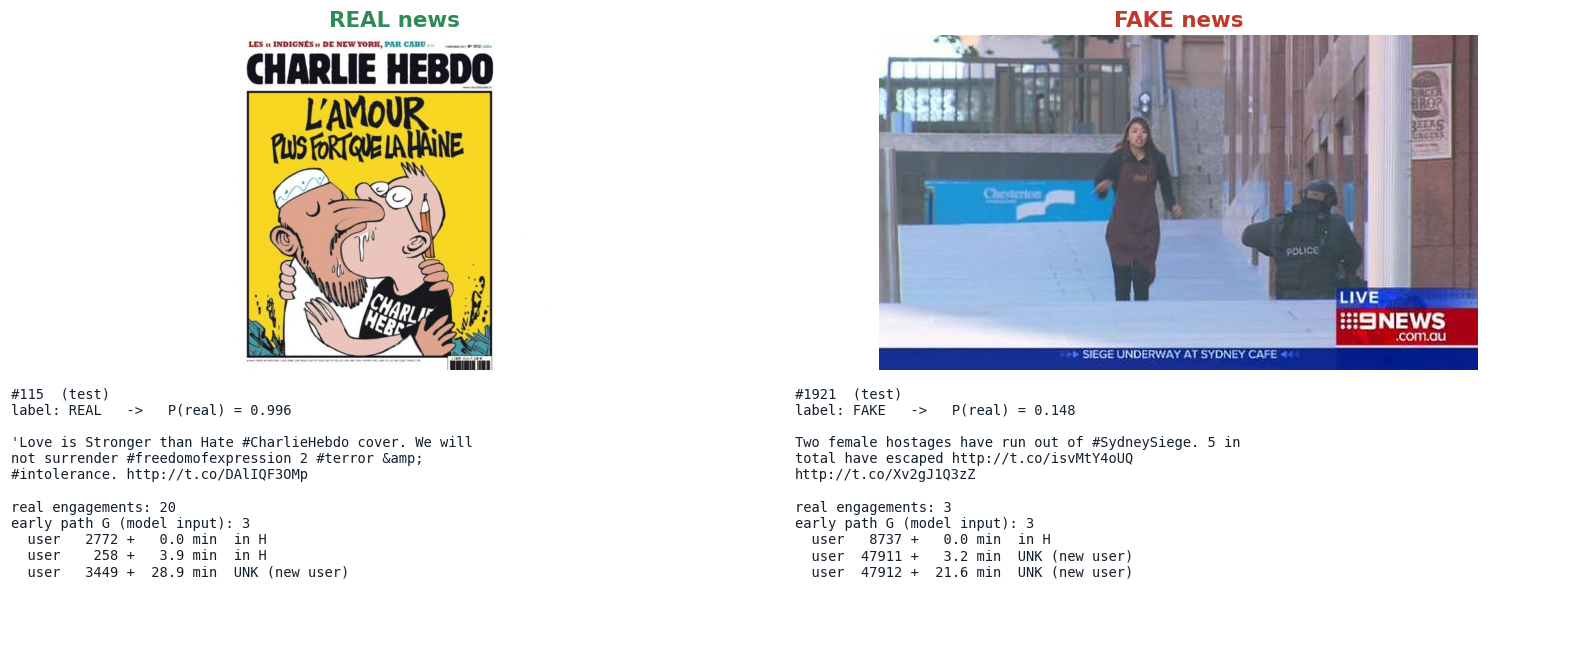

In [ ]:
# คู่ข่าวที่ใช้ตลอด notebook: REAL 1 ข่าว + FAKE 1 ข่าว (จาก test split)
if DATASET == 'pheme':
    REAL = B.find('Love is Stronger than Hate #CharlieHebdo cover. We will not')   # news #115 = ตัวอย่างในสไลด์
    FAKE = B.find('Two female hostages have run out')
else:
    REAL = next(d['index'] for d in B.demo if d['label'] == 'real')
    FAKE = next(d['index'] for d in B.demo if d['label'] == 'fake')
PAIR = [REAL, FAKE]
viz.show_pair(B, PAIR, [B.predict(k) for k in PAIR])

#### 🔧 Code ที่ใช้รันจริง · เตรียมข้อมูล input

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

**`src/data/components/politifact.py`** · อ่านข่าว + engagement · split 7:1:2 · กราฟ H (train เท่านั้น) · meta-path RWR · Λ(t) · early 3-5

In [ ]:
%%writefile code_used/src/data/components/politifact.py
"""PolitiFact preprocessing for RPPG-Fake.

Builds everything the three RPPG-Fake modules need from the files shipped in ``data/data.zip``
(extracted to ``data/politifact/``):

* the news table (id, text, label, time-ordered engagements),
* a stratified 7:1:2 train / val / test split (paper Sec. IV-A3),
* the heterogeneous social graph H, built from *training* news only so that no
  validation / test propagation leaks into user embeddings or path generation (Sec. III-A),
* meta-path neighbours sampled with random walk with restart (RWR) (Sec. III-A2),
* the per-news temporal engagement lists Lambda(t) used by the temporal reward (Eq. 12),
* the early-stage engagements (3-5 earliest real users) used at the early detection stage (Sec. IV-B).

Notes on the released data
--------------------------
* In ``actions_id`` every cascade starts from ``head_user == 1``: user 1 is a placeholder for the news
  itself, not a real publisher. The data therefore has **no publisher nodes**, so the paper's PNU
  meta-path cannot be built. The user-user repost relation (UU) is used as the third view instead.
* News id 14940 appears twice; the first occurrence is kept (483 unique news).

Run directly to build and cache the processed file for one seed::

    python -m src.data.components.politifact --seed 0
"""
from __future__ import annotations

import argparse
import ast
import csv
import os
import random
from collections import Counter, defaultdict
from typing import Dict, List, Sequence

import numpy as np
import torch

csv.field_size_limit(2**31 - 1)

NEWS_ROOT = 1  # head_user id that stands for the news item itself
REL_REPOST, REL_ENGAGE = 0, 1


# ----------------------------------------------------------------------------- news table
def load_news(raw_dir: str) -> List[dict]:
    """Read ``news_actions_<dataset>.csv``; drop duplicated ids; keep engagements in time order.

    PolitiFact comes with the repository; PHEME and GossipCop are converted to the same format by
    ``scripts/convert_pheme.py`` and ``scripts/convert_upfd.py``.
    """
    import glob
    found = sorted(glob.glob(os.path.join(raw_dir, "news_actions_*.csv")))
    if len(found) != 1:
        raise FileNotFoundError(f"expected exactly one news_actions_*.csv in {raw_dir}, found {found}")
    path = found[0]
    news, seen = [], set()
    with open(path, encoding="utf-8") as f:
        for row in csv.DictReader(f):
            if row["id"] in seen:
                continue
            seen.add(row["id"])
            acts = ast.literal_eval(row["actions_id"])
            eng = sorted(
                ((int(a["head_user"]), int(a["user"]), int(a["time"])) for a in acts), key=lambda x: x[2]
            )
            news.append({"id": row["id"], "text": row["text"], "label": int(row["label"]), "eng": eng})
    return news


def stratified_split(labels: Sequence[int], seed: int, ratios=(0.7, 0.1, 0.2)) -> Dict[str, List[int]]:
    """Random split with the paper's 7:1:2 ratio, stratified by label so every split keeps the class mix."""
    rng = random.Random(seed)
    by_label = defaultdict(list)
    for i, y in enumerate(labels):
        by_label[y].append(i)
    out = {"train": [], "val": [], "test": []}
    for idx in by_label.values():
        rng.shuffle(idx)
        n_tr = round(len(idx) * ratios[0])
        n_va = round(len(idx) * ratios[1])
        out["train"] += idx[:n_tr]
        out["val"] += idx[n_tr : n_tr + n_va]
        out["test"] += idx[n_tr + n_va :]
    for k in out:
        out[k].sort()
    return out


# ----------------------------------------------------------------------------- graph H
def build_graph(news: List[dict], train_idx: Sequence[int], num_users: int):
    """Heterogeneous graph H = (V, E) over users and news (Sec. III-A).

    Node ids: users keep their integer id (0 .. num_users-1); news item i is node ``num_users + i``.
    Edge types: REL_ENGAGE (news - user who engaged it) and REL_REPOST (user - user it was reposted from).
    Only training news contribute edges. Each edge also records the news it came from so the generator
    can exclude a news item's own cascade when it simulates that news (no self-leakage during training).
    """
    src, dst, rel, origin = [], [], [], []
    for i in train_idx:
        n_node = num_users + i
        users = set()
        for h, u, _ in news[i]["eng"]:
            users.add(u)
            if h != NEWS_ROOT:
                users.add(h)
                src.append(h), dst.append(u), rel.append(REL_REPOST), origin.append(i)
        for u in users:
            src.append(n_node), dst.append(u), rel.append(REL_ENGAGE), origin.append(i)
    src, dst = np.asarray(src, np.int64), np.asarray(dst, np.int64)
    rel, origin = np.asarray(rel, np.int64), np.asarray(origin, np.int64)
    # undirected: add reverse edges
    ei = np.stack([np.concatenate([src, dst]), np.concatenate([dst, src])])
    return {
        "edge_index": torch.from_numpy(ei),
        "edge_type": torch.from_numpy(np.concatenate([rel, rel])),
        "edge_origin": torch.from_numpy(np.concatenate([origin, origin])),
        # True for the original direction (head_user -> user, news -> user); used for "outgoing" actions
        "edge_forward": torch.from_numpy(np.r_[np.ones(len(src), bool), np.zeros(len(src), bool)]),
    }


def _csr(rows: np.ndarray, cols: np.ndarray, n: int):
    order = np.argsort(rows, kind="stable")
    rows, cols = rows[order], cols[order]
    ptr = np.zeros(n + 1, np.int64)
    np.add.at(ptr, rows + 1, 1)
    return np.cumsum(ptr), cols, order


def _walk(ptr, col, cur, rng):
    """One random hop for every walker in ``cur`` (walkers on dead ends stay put)."""
    deg = ptr[cur + 1] - ptr[cur]
    ok = deg > 0
    nxt = cur.copy()
    off = (rng.random(ok.sum()) * deg[ok]).astype(np.int64)
    nxt[ok] = col[ptr[cur[ok]] + off]
    return nxt, ok


def metapath_neighbors(graph: dict, num_users: int, num_news: int, seed: int,
                       walks: int = 20, restart: float = 0.3, top_k: int = 10) -> Dict[str, torch.Tensor]:
    """Meta-path guided RWR (Sec. III-A2) -> one semantic graph per meta-path.

    UNU : user -> news -> user      (co-engagement)
    NUN : news -> user -> news      (shared audience)
    UU  : user -> user              (repost relation; stands in for PNU, see module docstring)
    For each start node, ``walks`` meta-path instances are sampled; at every hop the walker restarts at
    the start node with probability ``restart``. The ``top_k`` most visited end nodes become neighbours.
    """
    rng = np.random.default_rng(seed)
    n_all = num_users + num_news
    ei, et = graph["edge_index"].numpy(), graph["edge_type"].numpy()
    eng = et == REL_ENGAGE
    rep = et == REL_REPOST
    # engage edges go both ways (news->user and user->news); split them by direction
    u2n = eng & (ei[0] < num_users)
    n2u = eng & (ei[0] >= num_users)
    csr = {
        "u2n": _csr(ei[0][u2n], ei[1][u2n], n_all)[:2],
        "n2u": _csr(ei[0][n2u], ei[1][n2u], n_all)[:2],
        "u2u": _csr(ei[0][rep], ei[1][rep], n_all)[:2],
    }
    patterns = {"UNU": ["u2n", "n2u"], "NUN": ["n2u", "u2n"], "UU": ["u2u"]}
    starts_of = {
        "UNU": np.unique(ei[0][u2n]),
        "NUN": np.unique(ei[0][n2u]),
        "UU": np.unique(ei[0][rep]),
    }
    out = {}
    for name, pat in patterns.items():
        starts = starts_of[name]
        if len(starts) == 0:
            out[name] = torch.zeros(2, 0, dtype=torch.long)
            continue
        walker_start = np.repeat(starts, walks)
        cur = walker_start.copy()
        ends = []
        for rep_i in range(2):  # two meta-path instances per walk (RWR may restart in between)
            alive = np.ones_like(cur, dtype=bool)
            for hop in pat:
                ptr, col = csr[hop]
                cur, ok = _walk(ptr, col, cur, rng)
                alive &= ok
            ends.append(np.where(alive, cur, -1))
            restart_mask = rng.random(len(cur)) < restart
            cur = np.where(restart_mask | ~alive, walker_start, cur)
        s = np.concatenate([walker_start, walker_start])
        e = np.concatenate(ends)
        keep = (e >= 0) & (e != s)
        s, e = s[keep], e[keep]
        # top-k most frequent ends per start
        pair = s * n_all + e
        uniq, cnt = np.unique(pair, return_counts=True)
        s_u, e_u = uniq // n_all, uniq % n_all
        order = np.lexsort((-cnt, s_u))
        s_u, e_u = s_u[order], e_u[order]
        first = np.r_[0, np.flatnonzero(np.diff(s_u)) + 1]
        rank = np.arange(len(s_u)) - np.repeat(first, np.diff(np.r_[first, len(s_u)]))
        sel = rank < top_k
        s_u, e_u = s_u[sel], e_u[sel]
        ei_l = np.stack([np.concatenate([s_u, e_u]), np.concatenate([e_u, s_u])])
        ei_l = np.unique(ei_l, axis=1)
        out[name] = torch.from_numpy(ei_l)
    return out


# ----------------------------------------------------------------------------- temporal + early
def temporal_slots(eng: List[tuple], n_slots: int, mode: str = "time", max_users: int = None) -> List[List[int]]:
    """Lambda(t): users engaging at time step t of the real cascade (Eq. 12).

    The generator simulates the first ``max_users`` (= T) engagements in ``n_slots`` (= T / K2) action
    steps, so Lambda(t) is built from that same part of the real cascade; otherwise step t would be
    compared with users from months later that never appear in a T-user early path.
    mode="time" (paper): "we divide the propagation temporal process evenly" -> ``n_slots`` equal
    wall-clock intervals between the first and the last of these engagements. Cascades have long tails, so many
    intervals are empty; an empty interval reuses the users of the closest earlier non-empty one so that
    the temporal reward stays defined.
    mode="rank": equal number of engagements per step (alternative, not in the paper).
    """
    if max_users:
        eng = eng[:max_users]
    users = [u for _, u, _ in eng]
    if not users:
        return [[] for _ in range(n_slots)]
    if mode == "rank":
        chunks = np.array_split(np.arange(len(users)), n_slots)
        return [[users[j] for j in c] for c in chunks]
    t = np.array([x[2] for x in eng], dtype=np.float64)
    span = t.max() - t.min()
    b = np.zeros(len(t), np.int64) if span == 0 else np.minimum(((t - t.min()) / span * n_slots).astype(np.int64), n_slots - 1)
    slots = [[] for _ in range(n_slots)]
    for u, k in zip(users, b):
        slots[k].append(u)
    for k in range(1, n_slots):
        if not slots[k]:
            slots[k] = slots[k - 1]
    return slots


def early_engagements(eng: List[tuple], rng: random.Random, lo: int = 3, hi: int = 5) -> List[tuple]:
    """Early detection stage: keep the first k in [lo, hi] real engagements (Sec. IV-B)."""
    k = rng.randint(lo, hi)
    return eng[:k]


# ----------------------------------------------------------------------------- build / cache
def build(raw_dir: str, out_dir: str, seed: int, n_slots: int = 20, slot_mode: str = "time", slot_users: int = 200, rwr_walks: int = 20,
          rwr_restart: float = 0.3, rwr_top_k: int = 10, force: bool = False) -> str:
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"seed{seed}_{slot_mode}{n_slots}_T{slot_users}.pt")
    if os.path.exists(path) and not force:
        return path
    news = load_news(raw_dir)
    num_users = 1 + max(max(max(h, u) for h, u, _ in n["eng"]) for n in news)
    labels = [n["label"] for n in news]
    split = stratified_split(labels, seed)
    graph = build_graph(news, split["train"], num_users)
    meta = metapath_neighbors(graph, num_users, len(news), seed, rwr_walks, rwr_restart, rwr_top_k)
    rng = random.Random(seed)
    early = [early_engagements(n["eng"], rng) for n in news]
    data = {
        "seed": seed,
        "num_users": num_users,
        "num_news": len(news),
        "ids": [n["id"] for n in news],
        "texts": [n["text"] for n in news],
        "labels": torch.tensor(labels),
        "split": split,
        "graph": graph,
        "meta": meta,
        "eng": [n["eng"] for n in news],
        "early": early,
        "slots": [temporal_slots(n["eng"], n_slots, slot_mode, slot_users) for n in news],
        "n_slots": n_slots,
        "slot_mode": slot_mode,
        "slot_users": slot_users,
    }
    torch.save(data, path)
    return path


def describe(data: dict) -> str:
    sp, y = data["split"], data["labels"].tolist()
    lines = [f"news={data['num_news']}  users={data['num_users']}  H edges={data['graph']['edge_index'].shape[1]}"]
    for k in ("train", "val", "test"):
        c = Counter(y[i] for i in sp[k])
        lines.append(f"  {k:5s} {len(sp[k]):4d}  fake={c[0]}  real={c[1]}")
    lines.append("  meta-path edges: " + ", ".join(f"{k}={v.shape[1]}" for k, v in data["meta"].items()))
    return "\n".join(lines)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw_dir", default="data/politifact")
    ap.add_argument("--out_dir", default="data/politifact/processed")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--n_slots", type=int, default=20)
    ap.add_argument("--slot_mode", default="time", choices=["time", "rank"])
    ap.add_argument("--slot_users", type=int, default=200)
    ap.add_argument("--force", action="store_true")
    a = ap.parse_args()
    p = build(a.raw_dir, a.out_dir, a.seed, n_slots=a.n_slots, slot_mode=a.slot_mode, slot_users=a.slot_users, force=a.force)
    print(p)
    print(describe(torch.load(p, weights_only=False)))


**`src/data/components/encode_content.py`** · CLIP ViT-B/32: n = [n_T ; n_V]

In [ ]:
%%writefile code_used/src/data/components/encode_content.py
"""Encode news content once with frozen CLIP ViT-B/32 and cache it.

n = [n_T ; n_V] (Sec. III-D3). The paper takes content features from its multimodal encoder [28];
CLIP ViT-B/32 is what the official code loads. CLIP's text encoder reads at most 77 tokens, so long
articles are truncated. The released PolitiFact data has no images, so n_V is a zero vector unless an
image directory with ``<news_id>.<ext>`` files is given.

    python -m src.data.components.encode_content --processed data/politifact/processed/seed0.pt
"""
from __future__ import annotations

import argparse
import fnmatch
import os

import torch


@torch.no_grad()
def _chunks(text: str, n: int, words: int = 50):
    """First ``n`` windows of ``words`` words (each fits CLIP's 77-token context in practice)."""
    w = str(text).split()
    out = [" ".join(w[i : i + words]) for i in range(0, max(len(w), 1), words)][:n]
    return out or [""]


def encode(texts, ids, image_dir=None, device="cuda", batch_size=64, text_chunks: int = 1):
    import clip
    from PIL import Image

    model, preprocess = clip.load("ViT-B/32", device=device)
    model.eval()
    # text_chunks = 1: CLIP reads the first 77 tokens (as the official code). text_chunks > 1: long articles are
    # split into windows that each fit the context and the window features are averaged (not in the paper).
    pieces, owner = [], []
    for j, t in enumerate(texts):
        cs = _chunks(t, text_chunks) if text_chunks > 1 else [t]
        pieces += cs
        owner += [j] * len(cs)
    feats = []
    with torch.no_grad():
        for i in range(0, len(pieces), batch_size):
            tok = clip.tokenize(pieces[i : i + batch_size], context_length=77, truncate=True).to(device)
            feats.append(model.encode_text(tok).float().cpu())
    flat = torch.cat(feats)
    text = torch.zeros(len(texts), flat.size(1)).index_add_(0, torch.tensor(owner), flat)
    text = text / torch.bincount(torch.tensor(owner), minlength=len(texts)).clamp_min(1).unsqueeze(1).float()
    image = torch.zeros_like(text)
    has_image = torch.zeros(len(ids), dtype=torch.bool)
    if image_dir and os.path.isdir(image_dir):
        files = os.listdir(image_dir)
        for j, nid in enumerate(ids):
            match = fnmatch.filter(files, f"{nid}.*")
            if not match:
                continue
            try:
                img = preprocess(Image.open(os.path.join(image_dir, match[0])).convert("RGB")).unsqueeze(0)
            except Exception:
                continue
            with torch.no_grad():
                image[j] = model.encode_image(img.to(device)).float().cpu()[0]
            has_image[j] = True
    return {"text": text, "image": image, "has_image": has_image}


def cached(processed_path: str, image_dir=None, device="cuda", text_chunks: int = 1) -> dict:
    """Content features live next to the processed split file and are shared by every seed."""
    tag = ("_img" if image_dir and os.path.isdir(image_dir) else "") + (f"_c{text_chunks}" if text_chunks > 1 else "")
    out = os.path.join(os.path.dirname(processed_path), f"content_clip_vitb32{tag}.pt")
    if os.path.exists(out):
        return torch.load(out, weights_only=False)
    data = torch.load(processed_path, weights_only=False)
    feats = encode(data["texts"], data["ids"], image_dir, device, text_chunks=text_chunks)
    torch.save(feats, out)
    return feats


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--processed", default="data/politifact/processed/seed0.pt")
    ap.add_argument("--image_dir", default=None)
    a = ap.parse_args()
    f = cached(a.processed, a.image_dir)
    print({k: tuple(v.shape) for k, v in f.items()}, "images found:", int(f["has_image"].sum()))


## 2. Module 1 · Heterogeneous Graph Contrastive Learning

กราฟ H สร้างจากข่าว **train เท่านั้น**: node = user และข่าว · edge = U-N (user แชร์ข่าว) และ U-U (repost ต่อจากกัน)
Module 1 เรียน embedding ของ user จาก 2 มุมมอง (node view + meta-path view) แบบ contrastive โดยไม่ใช้ label

**2.1** กราฟ H รอบ user คนแรก (ที่อยู่ใน H) ของข่าว REAL และ FAKE · สีของข่าว = label ของข่าว train ที่ user เคยแชร์

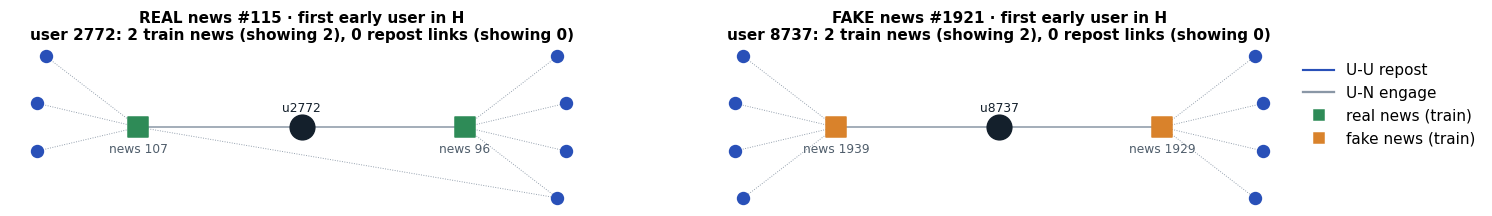

In [ ]:
viz.plot_ego_pair(B, PAIR)

**2.2** user embedding ทั้งหมด (ลดเหลือ 2 มิติด้วย t-SNE) · สี = สัดส่วนข่าว fake ที่ user เคยแชร์ใน train
ดาวเขียว = user ของข่าว REAL · ดาวแดง = user ของข่าว FAKE (พร้อมเพื่อนบ้านใกล้สุด 5 คน) · ใช้เวลา ~1 นาที

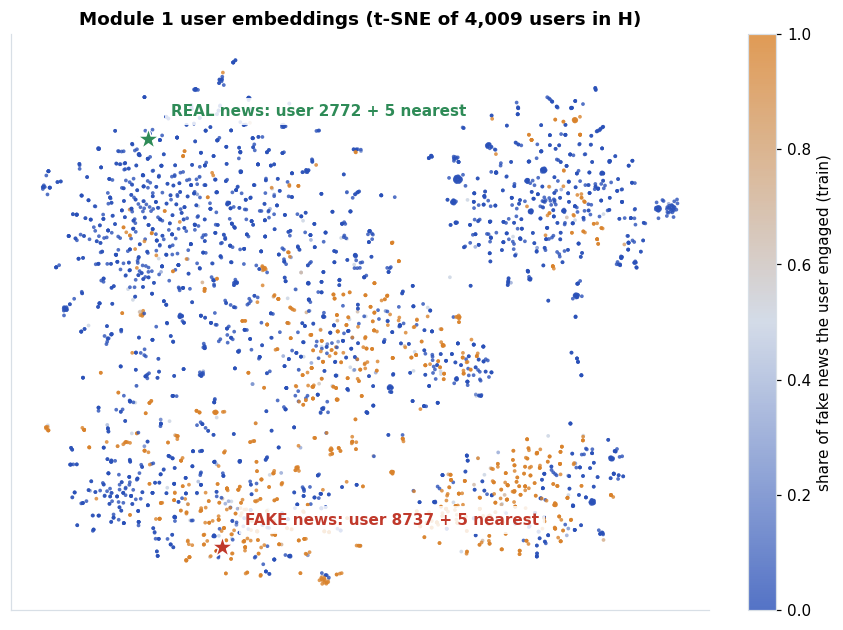

In [ ]:
U_REAL, U_FAKE = B.first_known_user(REAL), B.first_known_user(FAKE)
viz.plot_user_tsne(B, n=4000, highlight=[(U_REAL, 'REAL news', viz.GREEN), (U_FAKE, 'FAKE news', viz.RED)])

In [ ]:
# เพื่อนบ้านใกล้สุดของ user ทั้งสองคน (cosine ของ user vector ที่ Module 2 / 3 ใช้)
share, tot = B.fake_share()
rows = []
for lab, u in [('REAL news', U_REAL), ('FAKE news', U_FAKE)]:
    if u is None:
        continue
    rows.append({'news': lab, 'user': u, 'role': 'early user', 'cosine': 1.0, 'train news': int(tot[u]), 'fake share': round(share[u], 2)})
    rows += [{'news': lab, 'user': v, 'role': 'neighbour', 'cosine': round(c, 3), 'train news': int(tot[v]), 'fake share': round(share[v], 2)}
             for v, c in B.neighbours(u, 5)]
pd.DataFrame(rows)

,news,user,role,cosine,train news,fake share
0,REAL news,2772,early user,1.000,2,0.0
1,REAL news,2392,neighbour,0.881,1,0.0
2,REAL news,3334,neighbour,0.877,1,0.0
3,REAL news,3338,neighbour,0.877,1,0.0
4,REAL news,482,neighbour,0.877,1,0.0
5,REAL news,3297,neighbour,0.876,1,0.0
6,FAKE news,8737,early user,1.000,2,1.0
7,FAKE news,48157,neighbour,0.898,1,1.0
8,FAKE news,48160,neighbour,0.888,1,1.0
9,FAKE news,48159,neighbour,0.885,1,1.0


**2.3** user ที่ embedding ใกล้ **เนื้อหาข่าว** ที่สุด: เป็น action แบบ content ให้ Module 2 เริ่มสร้างเส้นทางได้แม้ยังไม่มีคนแชร์

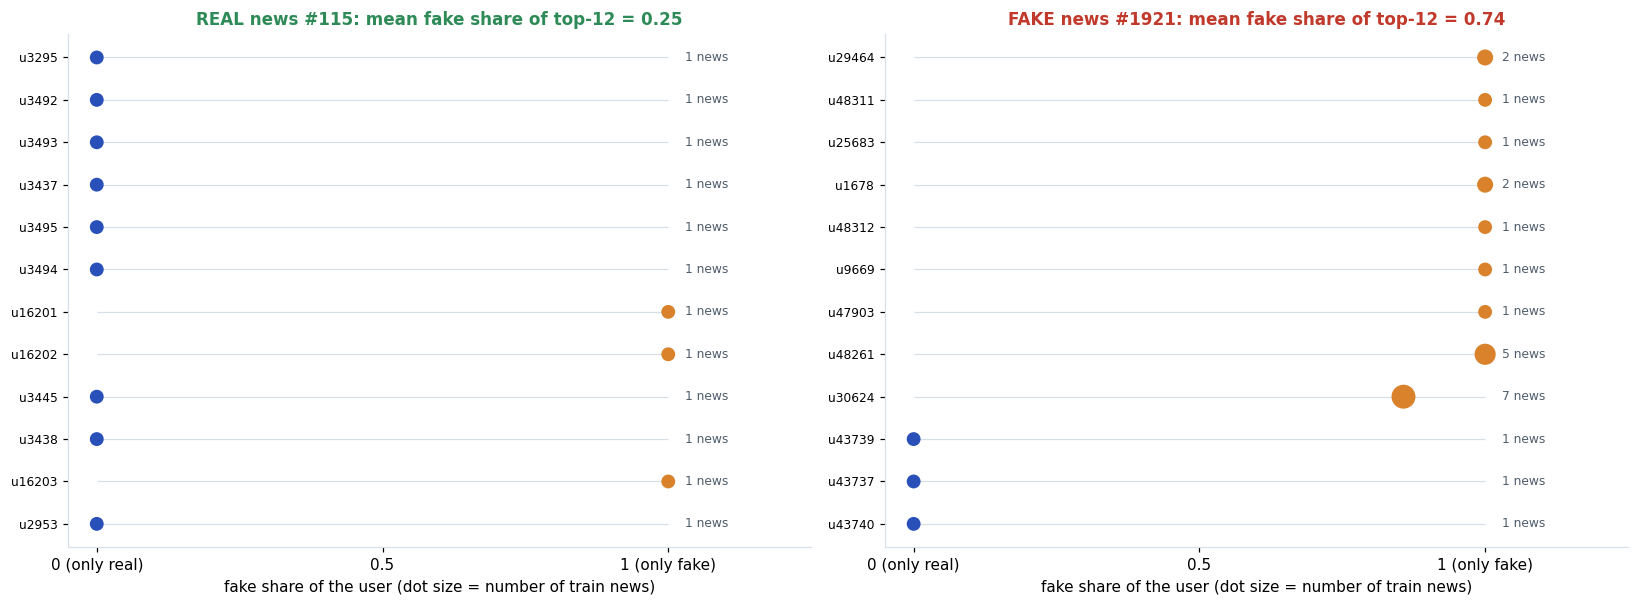

In [ ]:
viz.plot_content_candidates_pair(B, PAIR, k=12)

#### 🔧 Code ที่ใช้รันจริง · Heterogeneous Graph Contrastive Learning

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

**`src/models/components/rppg/layers.py`** · GAT ตาม Eq. 2 และ attention pooling (ใช้ใน Eq. 9)

In [ ]:
%%writefile code_used/src/models/components/rppg/layers.py
"""Building blocks shared by the three RPPG-Fake modules."""
from __future__ import annotations

import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import MessagePassing
from torch_geometric.utils import add_self_loops, remove_self_loops, scatter, softmax


class PaperGATConv(MessagePassing):
    """Graph attention layer exactly as written in Eq. (2):

        u._k     = ReLU([W1 u_k ; W1 u_i])
        alpha_ik = exp(a^T u._k) / sum_{k in N(i)} exp(a^T u._k)
        u_i^L    = sum_{k in N(i)} alpha_ik W1 u_k          (the outer sigma is applied by GATEncoder)

    a = [a_src ; a_dst] splits over the concatenation, so the score is a_src.ReLU(W u_k) + a_dst.ReLU(W u_i).
    Self-loops are added so every node attends to itself as well.
    """

    def __init__(self, in_dim: int, out_dim: int, heads: int = 1, concat: bool = True, dropout: float = 0.0):
        super().__init__(aggr="add", node_dim=0)
        self.heads, self.out_dim, self.concat, self.dropout = heads, out_dim, concat, dropout
        self.lin = nn.Linear(in_dim, heads * out_dim, bias=False)
        self.a_src = nn.Parameter(torch.empty(1, heads, out_dim))
        self.a_dst = nn.Parameter(torch.empty(1, heads, out_dim))
        self.bias = nn.Parameter(torch.zeros(heads * out_dim if concat else out_dim))
        nn.init.xavier_uniform_(self.lin.weight)
        nn.init.xavier_uniform_(self.a_src)
        nn.init.xavier_uniform_(self.a_dst)

    def forward(self, x, edge_index):
        h = self.lin(x).view(-1, self.heads, self.out_dim)
        edge_index, _ = remove_self_loops(edge_index)
        edge_index, _ = add_self_loops(edge_index, num_nodes=x.size(0))
        r = F.relu(h)
        e_src = (r * self.a_src).sum(-1)
        e_dst = (r * self.a_dst).sum(-1)
        out = self.propagate(edge_index, h=h, e_src=e_src, e_dst=e_dst)
        out = out.reshape(-1, self.heads * self.out_dim) if self.concat else out.mean(1)
        return out + self.bias

    def message(self, h_j, e_src_j, e_dst_i, index, ptr, size_i):
        alpha = softmax(e_src_j + e_dst_i, index, ptr, size_i)
        alpha = F.dropout(alpha, self.dropout, self.training)
        return h_j * alpha.unsqueeze(-1)


class GATEncoder(nn.Module):
    """Two-layer graph attention network (Eq. 2): multi-head first layer, single-head output layer."""

    def __init__(self, in_dim: int = 128, hidden: int = 128, out_dim: int = 128, heads: int = 4, dropout: float = 0.2):
        super().__init__()
        self.conv1 = PaperGATConv(in_dim, hidden // heads, heads=heads, dropout=dropout)
        self.conv2 = PaperGATConv(hidden, out_dim, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, self.dropout, self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, self.dropout, self.training)
        return self.conv2(x, edge_index)


class SubgraphAttentionPool(nn.Module):
    """Subgraph embedding Pi_t (Eq. 9).

    Each node is first refined with its neighbours inside the subgraph,
        u~_h = tanh(W0 [u_h ; sum_{u in N(u_h)} u]),
    then all nodes are aggregated with attention weights
        beta(u_h) = softmax(w . ELU(W1 u~_h)),   Pi = sum_h beta(u_h) u~_h.
    Works on a batch of graphs given as flat node features + ``batch`` vector.
    """

    def __init__(self, dim: int = 128):
        super().__init__()
        self.W0 = nn.Linear(2 * dim, dim)
        self.W1 = nn.Linear(dim, dim)
        self.w = nn.Linear(dim, 1, bias=False)

    def forward(self, x, edge_index, batch, num_graphs: int):
        n = x.size(0)
        if edge_index.numel():
            edge_index = torch.cat([edge_index, edge_index.flip(0)], 1)  # neighbourhood N(u_h) is undirected
            nb = scatter(x[edge_index[0]], edge_index[1], dim=0, dim_size=n, reduce="sum")
        else:
            nb = torch.zeros_like(x)
        u = torch.tanh(self.W0(torch.cat([x, nb], -1)))
        score = self.w(F.elu(self.W1(u))).squeeze(-1)
        score = score - scatter(score, batch, dim=0, dim_size=num_graphs, reduce="max")[batch]
        e = score.exp()
        beta = e / scatter(e, batch, dim=0, dim_size=num_graphs, reduce="sum")[batch].clamp_min(1e-12)
        return scatter(beta.unsqueeze(-1) * u, batch, dim=0, dim_size=num_graphs, reduce="sum")


**`src/models/components/rppg/contrastive.py`** · node view + PGD (Eq. 2-3), meta-path view (Eq. 4), L_CL (Eq. 5)

In [ ]:
%%writefile code_used/src/models/components/rppg/contrastive.py
"""Module 1 - Heterogeneous graph contrastive learning (Sec. III-A, Eqs. 2-5)."""
from __future__ import annotations

import torch
import torch.nn.functional as F
from torch import nn

from src.models.components.rppg.layers import GATEncoder


class HeteroGraphContrastive(nn.Module):
    """Dual-view self-supervised contrastive learning on the social graph H.

    * Node view: PGD-perturbed node features u~ = u + delta [18]; for every centre node the top-K1 most and
      least cosine-similar nodes form the positive / negative sets [19] (similarity of the current, detached
      GAT embeddings of the clean graph, searched in a random pool of nodes); a GAT encodes the perturbed
      graph and the loss is Eq. (3) with temperature tau1.
    * Meta-path view: one GAT per meta-path semantic graph H^l; the same node under two meta-paths is a
      positive pair, other nodes in the batch are negatives, Eq. (4) with temperature tau2.
    * L_CL = lambda1 * L_node + (1 - lambda1) * L_meta (Eq. 5).
    News nodes start from their (frozen) CLIP content feature, users from a learnable embedding table.
    """

    def __init__(self, num_users: int, num_news: int, content_dim: int, n_meta: int, dim: int = 128,
                 heads: int = 4, dropout: float = 0.2, tau1: float = 0.4, tau2: float = 0.3,
                 lambda1: float = 0.4, k1: int = 8, pgd_eps: float = 0.05, pgd_steps: int = 2,
                 pos_neg: str = "embedding"):
        super().__init__()
        # pos_neg="embedding": V^p / V^n by cosine of the model's own current embeddings (rounds 1-6). This is
        # self-reinforcing and collapsed the node view to ~1 dimension (found 2026-10-19).
        # pos_neg="structure": cosine of a fixed neighbourhood sketch (A + I) R of graph H (set_structure), so
        # nodes that share neighbours (same news / repost) are positives and unrelated nodes are negatives.
        self.pos_neg = pos_neg
        self.register_buffer("sketch", torch.zeros(0), persistent=False)
        self.num_users, self.num_news = num_users, num_news
        self.user_emb = nn.Embedding(num_users, dim)
        nn.init.normal_(self.user_emb.weight, std=0.1)
        self.content_proj = nn.Linear(content_dim, dim)
        self.node_gat = GATEncoder(dim, dim, dim, heads, dropout)
        self.meta_gats = nn.ModuleList([GATEncoder(dim, dim, dim, heads, dropout) for _ in range(n_meta)])
        self.tau1, self.tau2, self.lambda1, self.k1 = tau1, tau2, lambda1, k1
        self.pgd_eps, self.pgd_steps = pgd_eps, pgd_steps

    @torch.no_grad()
    def set_structure(self, edge_index, n_all: int, dim: int = 64, seed: int = 0):
        g = torch.Generator(device="cpu").manual_seed(seed)
        R = torch.randn(n_all, dim, generator=g).to(edge_index.device)
        S = R.clone()  # + I: a node's own id is part of its neighbourhood
        S.index_add_(0, edge_index[1], R[edge_index[0]])  # + A R (edge_index holds both directions)
        self.sketch = F.normalize(S, dim=-1)

    def features(self, content):
        return torch.cat([self.user_emb.weight, self.content_proj(content)], 0)

    # ------------------------------------------------------------------ node view (Eq. 2-3)
    @torch.no_grad()
    def _pos_neg(self, x, edge_index, centres, pool):
        """V_i^p / V_i^n: top-K1 most / least cosine-similar nodes to the centre (clean graph, detached)."""
        if self.pos_neg == "structure" and self.sketch.numel():
            z = self.sketch
        else:
            was = self.node_gat.training
            self.node_gat.eval()
            z = F.normalize(self.node_gat(x, edge_index), dim=-1)
            self.node_gat.train(was)
        xs = z[centres] @ z[pool].T
        same = pool.unsqueeze(0) == centres.unsqueeze(1)
        pos = torch.topk(xs.masked_fill(same, -2.0), self.k1, dim=1).indices
        neg = torch.topk(xs.masked_fill(same, 2.0), self.k1, dim=1, largest=False).indices
        return pos, neg

    def _node_loss(self, x, edge_index, centres, pool, pos, neg):
        z = F.normalize(self.node_gat(x, edge_index), dim=-1)
        sim = (z[centres] @ z[pool].T) / self.tau1
        pos_s = torch.logsumexp(sim.gather(1, pos), 1)
        neg_s = torch.logsumexp(sim.gather(1, neg), 1)
        return (neg_s - pos_s).mean()  # -log( sum_pos exp / sum_neg exp )

    def node_view_loss(self, content, edge_index, centres, pool):
        x = self.features(content)
        pos, neg = self._pos_neg(x.detach(), edge_index, centres, pool)
        if self.pgd_steps > 0 and self.training:  # PGD: ascend the contrastive loss inside an eps-ball
            delta = torch.zeros_like(x, requires_grad=True)
            step = self.pgd_eps / self.pgd_steps
            for _ in range(self.pgd_steps):
                loss = self._node_loss(x.detach() + delta, edge_index, centres, pool, pos, neg)
                g, = torch.autograd.grad(loss, delta)
                delta = (delta + step * g.sign()).clamp(-self.pgd_eps, self.pgd_eps).detach().requires_grad_(True)
            x = x + delta.detach()
        return self._node_loss(x, edge_index, centres, pool, pos, neg)

    # ------------------------------------------------------------------ meta-path view (Eq. 4)
    def meta_view_loss(self, content, meta_edges, batch):
        x = self.features(content)
        hs = [F.normalize(g(x, e)[batch], dim=-1) for g, e in zip(self.meta_gats, meta_edges)]
        loss, n = 0.0, 0
        eye = torch.eye(len(batch), dtype=torch.bool, device=x.device)
        for l in range(len(hs)):
            for m in range(len(hs)):
                if l == m:
                    continue
                sim = hs[l] @ hs[m].T / self.tau2
                pos = sim.diagonal()
                neg = torch.logsumexp(sim.masked_fill(eye, float("-inf")), 1)  # I[i != k]
                loss = loss + (neg - pos).mean()
                n += 1
        return loss / max(n, 1)

    def loss(self, content, edge_index, meta_edges, centres, pool, meta_batch):
        l_node = self.node_view_loss(content, edge_index, centres, pool)
        l_meta = self.meta_view_loss(content, meta_edges, meta_batch)
        return self.lambda1 * l_node + (1 - self.lambda1) * l_meta, l_node.detach(), l_meta.detach()

    @torch.no_grad()
    def embeddings(self, content, edge_index, meta_edges):
        """Node-view embedding u^ and sum_{l in Phi(u_i)} h^l (inputs of Eq. 7).

        Phi(u_i) = the meta-paths node i actually takes part in (it has at least one neighbour in H^l);
        e.g. users belong to UNU and UU but not to NUN.
        """
        x = self.features(content)
        node = self.node_gat(x, edge_index)
        meta = torch.zeros_like(node)
        for g, e in zip(self.meta_gats, meta_edges):
            member = torch.zeros(x.size(0), dtype=torch.bool, device=x.device)
            if e.numel():
                member[e[0]] = True
            meta = meta + g(x, e) * member.unsqueeze(-1)
        return node, meta


## 3. Module 2 · Reinforced Propagation Path Generation

MDP: state = กราฟเส้นทางปัจจุบัน + user ล่าสุด + เนื้อหาข่าว · action = เพิ่ม user ใหม่ผ่านความสัมพันธ์ใน H (repost / co-engage) หรือผ่านความใกล้เนื้อหา
policy (actor) เลือก K2 = 10 คนต่อ step จนครบ T = 200 คน · ตอน train ใช้ reward = λ2·R_T (ตรงกับคนที่แชร์ในช่วงเวลานั้น) + (1-λ2)·R_G (discriminator)

cell ด้านล่าง **สร้าง G′ ใหม่สด ๆ** ให้ทั้งข่าว REAL และ FAKE ด้วย policy ที่ train แล้ว (เปลี่ยน `seed` แล้วได้เส้นทางต่างกัน เพราะ policy สุ่มตาม π)

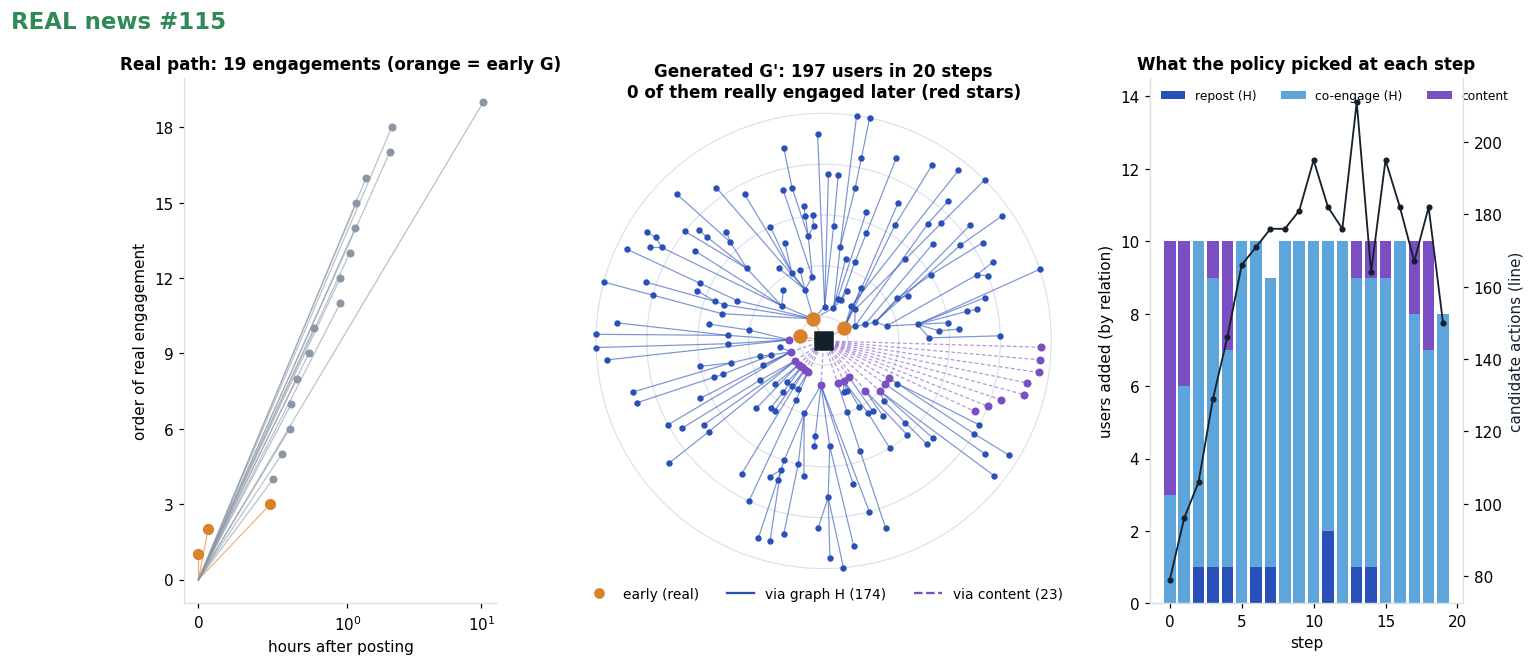

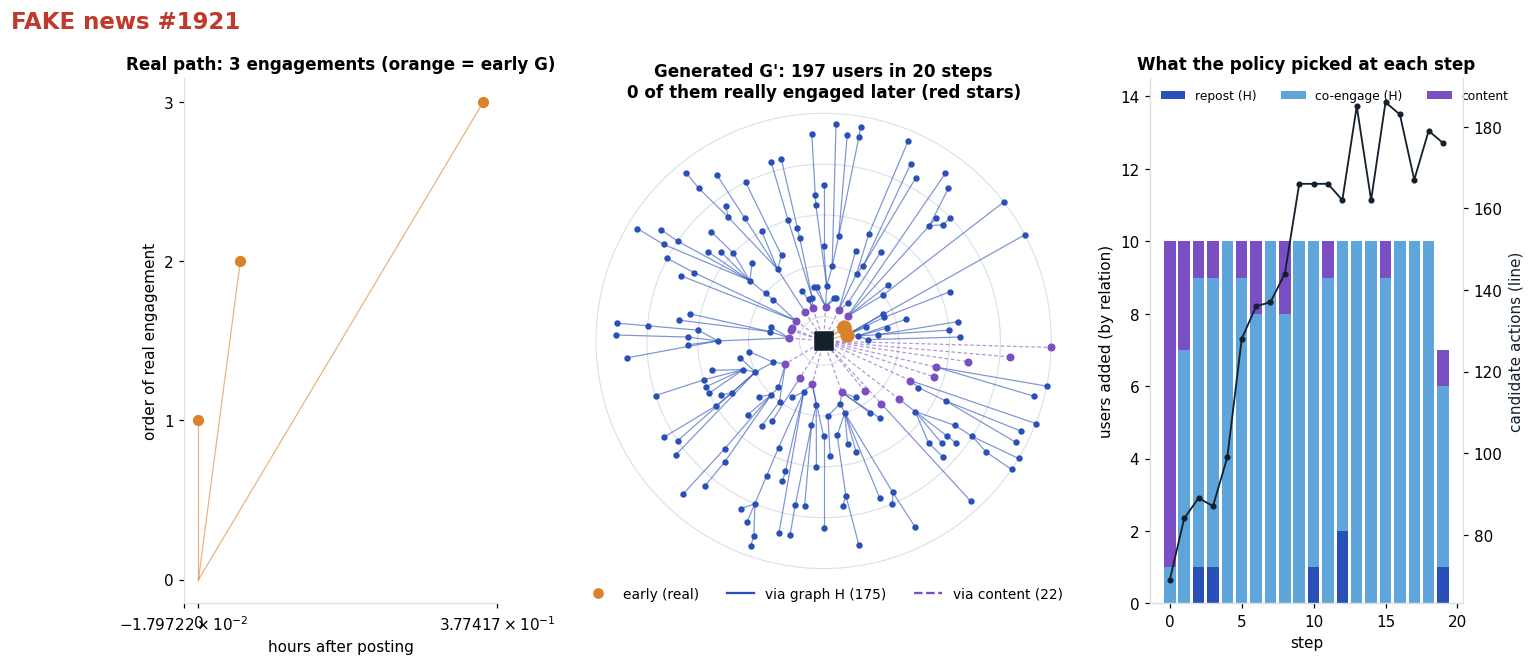

In [ ]:
GEN = {k: B.generate(k, seed=0) for k in PAIR}
for k in PAIR:
    viz.plot_generation(B, k, *GEN[k])

In [ ]:
# เทียบ REAL กับ FAKE: สร้าง user มาจากไหน ตรงกับคนแชร์จริงกี่คน และ policy มั่นใจแค่ไหน
def gen_summary(k, steps, rec):
    via_content = sum(p == -1 for st in steps for p, _ in st)
    n = sum(len(st) for st in steps)
    return {'news': f"#{k} {B.item(k)['label'].upper()}", 'early users in H': f"{B.known_share(k):.0%}",
            'generated users': n, 'via graph H': n - via_content, 'via content': via_content,
            'match real later users': len(B.hits(k, steps)), 'mean candidates / step': round(np.mean([r['n_candidates'] for r in rec]), 1),
            'mean entropy of π': round(np.mean([r['entropy'] for r in rec]), 2)}
pd.DataFrame([gen_summary(k, *GEN[k]) for k in PAIR]).set_index('news').T

news,#115 REAL,#1921 FAKE
early users in H,67%,33%
generated users,197,197
via graph H,174,175
via content,23,22
match real later users,0,0
mean candidates / step,161.5,143.6
mean entropy of π,4.98,4.85


In [ ]:
# ทั้ง test set (G′ ที่ Stage 1 สร้างไว้และใช้วัดผลจริง): ตรงกับคนแชร์จริงแค่ไหน แยกข่าว real / fake
test = list(B.data['split']['test'])
rows = []
for lab, v in [('real', 1), ('fake', 0)]:
    ks = [i for i in test if B.labels[i] == v]
    gen = sum(len(st) for i in ks for st in B.paths[i]['steps'])
    hit = sum(len(B.hits(i, B.paths[i]['steps'])) for i in ks)
    rows.append({'test news': lab, 'news': len(ks), 'generated users': gen, 'match real later users': hit, 'hit rate': f'{hit / max(gen, 1):.2%}'})
pd.DataFrame(rows)

,test news,news,generated users,match real later users,hit rate
0,real,282,55371,48,0.09%
1,fake,120,23549,24,0.10%


#### 🔧 Code ที่ใช้รันจริง · Reinforced Propagation Path Generation

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

**`src/models/components/rppg/generator.py`** · MDP (Eq. 6), policy (Eq. 7-11), reward (Eq. 12-14), actor-critic (Eq. 15-19)

In [ ]:
%%writefile code_used/src/models/components/rppg/generator.py
"""Module 2 - Reinforced propagation path generation (Sec. III-B and III-C, Eqs. 6-19)."""
from __future__ import annotations

import math
from typing import Dict, List, Optional

import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

from src.data.components.politifact import NEWS_ROOT, REL_ENGAGE, REL_REPOST
from src.models.components.rppg.layers import SubgraphAttentionPool

REL_COENGAGE, REL_CONTENT = 1, 2  # action relation types (repost = 0); index 3 = self-loop


def _csr(rows, cols, extra, n):
    order = np.argsort(rows, kind="stable")
    ptr = np.zeros(n + 1, np.int64)
    np.add.at(ptr, rows + 1, 1)
    return np.cumsum(ptr), cols[order], (extra[order] if extra is not None else None)


class PropagationEnv:
    """MDP environment on the training social graph H (Sec. III-B1).

    State s_t = (n, U_t, V_t, R_t); an action connects a user already in the path to a new user through an
    outgoing relation of H:
      * repost      (u_h -> u) : u reposted from u_h in some *other* training cascade (outgoing edge only)
      * co-engage   (u_h -> u) : u engaged a training news that u_h also engaged (U-N-U)
      * content     (n   -> u) : u is among the users whose embedding is closest to the news content; this
                                  lets generation start "even if no propagation paths exist" (Sec. III, B)
    Edges that come from the news being simulated are masked out, so the generator never sees that news'
    own real cascade through H. ``exclude[news]`` removes that news' real engagers from the content
    candidates: their embeddings were trained on H (which contains the training cascades), so for a
    training news they would be retrieved by content similarity although a test news never gets that
    advantage. Transitions are deterministic (Eq. 6).
    """

    def __init__(self, data: dict, content_topk: np.ndarray, max_sources: int = 64, max_repost: int = 8,
                 max_coengage: int = 6, max_actions: int = 256, exclude=None):
        U, N = data["num_users"], data["num_news"]
        ei = data["graph"]["edge_index"].numpy()
        et = data["graph"]["edge_type"].numpy()
        eo = data["graph"]["edge_origin"].numpy()
        fwd = data["graph"]["edge_forward"].numpy()
        rep = (et == REL_REPOST) & fwd
        u2n = (et == REL_ENGAGE) & (ei[0] < U)
        n2u = (et == REL_ENGAGE) & (ei[0] >= U)
        self.rep = _csr(ei[0][rep], ei[1][rep], eo[rep], U)
        self.u2n = _csr(ei[0][u2n], ei[1][u2n] - U, None, U)
        self.n2u = _csr(ei[0][n2u] - U, ei[1][n2u], None, N)
        self.content_topk = content_topk
        self.max_sources, self.max_repost = max_sources, max_repost
        self.max_coengage, self.max_actions = max_coengage, max_actions
        self.exclude = exclude or {}

    def candidates(self, news: int, path_users: np.ndarray, in_path: set, rng: np.random.Generator):
        """Return candidate (user, parent, relation) arrays for the current state."""
        users, parents, rels = [], [], []
        src = path_users if len(path_users) <= self.max_sources else rng.choice(path_users, self.max_sources, replace=False)
        ptr, col, org = self.rep
        uptr, ucol, _ = self.u2n
        nptr, ncol, _ = self.n2u
        for h in src:
            a, b = ptr[h], ptr[h + 1]
            if b > a:
                nb, o = col[a:b], org[a:b]
                nb = nb[o != news]
                if len(nb) > self.max_repost:
                    nb = rng.choice(nb, self.max_repost, replace=False)
                users.append(nb), parents.append(np.full(len(nb), h)), rels.append(np.full(len(nb), REL_REPOST))
            a, b = uptr[h], uptr[h + 1]
            if b > a:
                nws = ucol[a:b]
                nws = nws[nws != news]
                if len(nws):
                    m = nws[rng.integers(len(nws))]
                    na, nb_ = nptr[m], nptr[m + 1]
                    co = ncol[na:nb_]
                    if len(co) > self.max_coengage:
                        co = rng.choice(co, self.max_coengage, replace=False)
                    users.append(co), parents.append(np.full(len(co), h)), rels.append(np.full(len(co), REL_COENGAGE))
        ct = self.content_topk[news]
        if news in self.exclude:
            ct = ct[~np.isin(ct, self.exclude[news])]
        users.append(ct), parents.append(np.full(len(ct), -1)), rels.append(np.full(len(ct), REL_CONTENT))
        users, parents, rels = np.concatenate(users), np.concatenate(parents), np.concatenate(rels)
        keep = np.array([u not in in_path and u != NEWS_ROOT for u in users], dtype=bool)
        users, parents, rels = users[keep], parents[keep], rels[keep]
        users, first = np.unique(users, return_index=True)
        parents, rels = parents[first], rels[first]
        if len(users) > self.max_actions:
            sel = rng.choice(len(users), self.max_actions, replace=False)
            users, parents, rels = users[sel], parents[sel], rels[sel]
        return users, parents, rels


class PathGraph:
    """Growing propagation path G'_t: node 0 is the news seed, others are users (local indices)."""

    def __init__(self):
        self.users: List[int] = []
        self.index: Dict[int, int] = {}
        self.edges: List[tuple] = []  # local (parent, child)

    def add(self, user: int, parent: int) -> bool:
        if user in self.index:
            return False
        self.index[user] = len(self.users) + 1
        self.users.append(user)
        self.edges.append((self.index.get(parent, 0), self.index[user]))
        return True

    def tensors(self, device):
        ei = torch.tensor(self.edges, dtype=torch.long, device=device).T if self.edges else torch.zeros(2, 0, dtype=torch.long, device=device)
        return torch.tensor(self.users, dtype=torch.long, device=device), ei


class RPPGGenerator(nn.Module):
    """Policy network (Eqs. 7-11), critic (Eq. 15) and path discriminator D (Eq. 13)."""

    def __init__(self, base_dim: int = 128, content_dim: int = 1024, dim: int = 128, n_rel: int = 3,
                 standardize: bool = False):
        super().__init__()
        # standardize=True: z-score the Module 1 embeddings over users before Eq. 7. Without it the GAT outputs
        # share a large common component, tanh saturates and every user in H gets the same vector (found 2026-10-19).
        self.standardize = standardize
        # users that exist in graph H (train news); others share one "unknown" vector (set_known)
        self.register_buffer("known", torch.zeros(0, dtype=torch.bool), persistent=False)
        self.fuse = nn.Linear(2 * base_dim, dim)                 # Eq. 7: u_i = tanh(W_u [u^_i ; sum_l h^l_i])
        self.news_proj = nn.Linear(content_dim, dim)             # news content embedding n
        self.rel_emb = nn.Embedding(n_rel + 1, dim)              # r_i (last index = self-loop)
        self.self_loop = nn.Parameter(torch.zeros(dim))          # "no interaction happens" action
        self.state_pool = SubgraphAttentionPool(dim)             # Eq. 9
        self.actor = nn.Sequential(nn.Linear(4 * dim, dim), nn.ReLU(), nn.Linear(dim, 1))   # Eq. 11 (W3, W2)
        self.critic = nn.Sequential(nn.Linear(4 * dim, dim), nn.ReLU(), nn.Linear(dim, 1))  # Eq. 15 (W1Q, W0Q)
        self.disc_pool = SubgraphAttentionPool(dim)              # D shares the structure of Eq. 9
        self.disc_head = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, 1))
        self.n_rel = n_rel

    def set_known(self, mask):
        self.known = mask

    def user_table(self, base_node, base_meta):
        k = self.known if self.known.numel() else None
        if self.standardize:  # z-score with statistics of the users in H only (isolated users are ~70% of rows)
            def z(x):
                ref = x[k] if k is not None else x
                return (x - ref.mean(0)) / (ref.std(0) + 1e-6)
            base_node, base_meta = z(base_node), z(base_meta)
        U = torch.tanh(self.fuse(torch.cat([base_node, base_meta], -1)))
        if k is not None:  # users not in H (val/test-only, unseen) -> one shared UNK vector = mean of known users
            U = torch.where(k.unsqueeze(-1), U, U[k].mean(0, keepdim=True))
        return U

    def graph_nodes(self, g: PathGraph, U, n_vec):
        users, ei = g.tensors(U.device)
        x = torch.cat([n_vec.unsqueeze(0), U[users]], 0) if len(users) else n_vec.unsqueeze(0)
        return x, ei

    def state(self, g: PathGraph, new_users: List[int], U, n_vec):
        """s_t = [Pi_t ; v_t ; n] (Eqs. 8-10)."""
        x, ei = self.graph_nodes(g, U, n_vec)
        pi = self.state_pool(x, ei, torch.zeros(x.size(0), dtype=torch.long, device=x.device), 1)[0]
        v = U[torch.tensor(new_users, device=U.device)].mean(0) if new_users else torch.zeros_like(n_vec)
        return torch.cat([pi, v, n_vec])

    def action_embeddings(self, users, rels, U):
        a = U[torch.as_tensor(users, device=U.device)] + self.rel_emb(torch.as_tensor(rels, device=U.device))
        return torch.cat([a, (self.self_loop + self.rel_emb.weight[self.n_rel]).unsqueeze(0)], 0)

    def scores(self, net, s, a):
        return net(torch.cat([s.unsqueeze(0).expand(a.size(0), -1), a], -1)).squeeze(-1)

    def discriminate(self, graphs: List[PathGraph], U, n_vecs):
        xs, eis, bs, off = [], [], [], 0
        for i, g in enumerate(graphs):
            x, ei = self.graph_nodes(g, U, n_vecs[i])
            xs.append(x), eis.append(ei + off), bs.append(torch.full((x.size(0),), i, device=x.device))
            off += x.size(0)
        h = self.disc_pool(torch.cat(xs), torch.cat(eis, 1), torch.cat(bs), len(graphs))
        return self.disc_head(h).squeeze(-1)  # logit of D


def generated_prefix(early: List[tuple], steps: List[List[tuple]], size: int) -> PathGraph:
    """Generated path G'_t restricted to its first ``size`` users (input to D, Eq. 13)."""
    g = PathGraph()
    for h, u, _ in early:
        if len(g.users) >= size:
            return g
        g.add(u, -1 if h == NEWS_ROOT else h)
    for step in steps:
        for p, c in step:
            if len(g.users) >= size:
                return g
            g.add(c, p)
    return g


def real_prefix(eng: List[tuple], size: int) -> PathGraph:
    """Real propagation path restricted to its first ``size`` engaged users (input to D)."""
    g = PathGraph()
    for h, u, _ in eng:
        if len(g.users) >= size:
            break
        g.add(u, -1 if h == NEWS_ROOT else h)
    return g


def rollout(model: RPPGGenerator, env: PropagationEnv, news: int, early: List[tuple], U, n_vec,
            rng: np.random.Generator, T: int, K2: int, max_steps: int, slots: Optional[List[List[int]]] = None,
            lambda2: float = 0.4, gamma: float = 0.9, train: bool = True, global_reward: str = "eq13",
            real_users: Optional[set] = None, hit_weight: float = 0.0, policy: str = "rl"):
    """Generate one propagation path; when ``train`` also return actor / critic losses.

    Rewards (Sec. III-B3):
      R_T(u_i, t) = cos(u_i, mean_{u_j in Lambda(t)} u_j)            temporal reward (Eq. 12)
      R_G        = -log(1 - D(G'_t))                                   global reward (Eq. 13). Eq. 13 is
                   -(E_real log D(G) + E_gen log(1 - D(G'))); the first term does not depend on the generator,
                   so the generator receives the second term for its own path (computed as softplus(logit D)).
                   global_reward="scaled" uses 2*D - 1 instead (bounded like the cosine temporal reward)
      R_C        = lambda2 * R_T + (1 - lambda2) * R_G               (Eq. 14)
      + hit_weight * 1[u_i really engaged this training news]          (optional, NOT in the paper: a direct
                   supervision signal used to test whether a more faithful G' helps detection)
    Actor-critic (Sec. III-C): q_t = R_C + gamma * E_a[Q(s_{t+1}, a)] (Eq. 16), L_critic = (Q - q_t)^2 (Eq. 17),
    actor gradient Q(s_t, a_t) * grad log pi(s_t, a_t) (Eq. 19). K2 actions are absorbed per step [24].
    ``policy`` (generation only, Table IV): "rl" = learned policy, "random" = "Random Sample" (K2 random
    candidates per step), "similarity" = "Node Similarity" (top-K2 candidates most similar to the news).
    """
    g = PathGraph()
    for h, u, _ in early:
        g.add(u, -1 if h == NEWS_ROOT else h)
    new_users = list(g.users)
    steps: List[List[tuple]] = []
    recs = []
    for t in range(max_steps):
        if len(g.users) >= T:
            break
        users, parents, rels = env.candidates(news, np.asarray(g.users, dtype=np.int64), set(g.users), rng)
        if policy != "rl":
            k = min(K2, T - len(g.users), len(users))
            if k <= 0:
                break
            if policy == "random":
                pick = rng.choice(len(users), k, replace=False)
            else:
                sims = F.normalize(U[torch.as_tensor(users, device=U.device)], dim=-1) @ F.normalize(n_vec, dim=0)
                pick = torch.topk(sims, k).indices.cpu().numpy()
            step = []
            for j in pick.tolist():
                if g.add(int(users[j]), int(parents[j])):
                    step.append((int(parents[j]), int(users[j])))
            steps.append(step)
            continue
        s = model.state(g, new_users, U, n_vec)
        a = model.action_embeddings(users, rels, U)
        logits = model.scores(model.actor, s, a)
        probs = logits.softmax(-1)
        k = min(K2, T - len(g.users), a.size(0))
        with torch.no_grad():
            pick = torch.multinomial(probs, k, replacement=False)
        added, step = [], []
        for j in pick.tolist():
            if j == len(users):  # self-loop
                continue
            if g.add(int(users[j]), int(parents[j])):
                added.append(int(users[j]))
                step.append((int(parents[j]), int(users[j])))
        steps.append(step)
        if train:
            q = model.scores(model.critic, s, a[pick])
            v_all = (probs.detach() * model.scores(model.critic, s, a).detach()).sum()
            recs.append({"logp": probs[pick].clamp_min(1e-9).log(), "q": q, "pick": pick, "n_cand": len(users),
                         "users": users, "v": v_all, "t": t})
        new_users = added
        if not added and len(users) == 0:
            break
    if not train:
        return steps, g, None
    # ---------------- rewards
    with torch.no_grad():
        Ud = U.detach()
        n_slots = len(slots)
        r_g_steps = []
        prefix = PathGraph()
        for h, u, _ in early:
            prefix.add(u, -1 if h == NEWS_ROOT else h)
        for step in steps:
            for p, c in step:
                prefix.add(c, p)
            logit = model.discriminate([prefix], Ud, n_vec.detach().unsqueeze(0))[0]
            r_g_steps.append(F.softplus(logit) if global_reward == "eq13" else 2 * torch.sigmoid(logit) - 1)
    actor_loss, critic_loss = 0.0, 0.0
    for i, r in enumerate(recs):
        t = min(r["t"], n_slots - 1)
        lam = slots[t] if slots[t] else [u for sl in slots for u in sl]
        target = F.normalize(Ud[torch.tensor(lam, device=U.device)].mean(0), dim=0)
        rt = torch.zeros(len(r["pick"]), device=U.device)
        is_user = r["pick"] < r["n_cand"]
        if is_user.any():
            sel = torch.as_tensor(r["users"], device=U.device)[r["pick"][is_user]]
            rt[is_user] = F.normalize(Ud[sel], dim=-1) @ target
        rc = lambda2 * rt + (1 - lambda2) * r_g_steps[i]
        if hit_weight and real_users and is_user.any():
            hit = torch.zeros(len(r["pick"]), device=U.device)
            picked = np.asarray(r["users"])[r["pick"][is_user].cpu().numpy()]
            hit[is_user] = torch.tensor([float(u in real_users) for u in picked], device=U.device)
            rc = rc + hit_weight * hit
        nxt = recs[i + 1]["v"] if i + 1 < len(recs) else torch.zeros((), device=U.device)
        q_target = (rc + gamma * nxt).detach()
        critic_loss = critic_loss + F.mse_loss(r["q"], q_target, reduction="sum")
        actor_loss = actor_loss - (r["q"].detach() * r["logp"]).sum()
    return steps, g, {"actor": actor_loss, "critic": critic_loss, "reward_g": torch.stack(r_g_steps).mean() if r_g_steps else torch.zeros(())}


**`src/train_hete_RL.py`** · Stage 1 = Algorithm 1 บรรทัด 1-14: train Module 1 แล้ว Module 2 แล้วสร้าง G′ ทุกข่าว

In [ ]:
%%writefile code_used/src/train_hete_RL.py
"""Stage 1 of RPPG-Fake: user embeddings + reinforced propagation path generation (Algorithm 1, lines 1-14).

    python src/train_hete_RL.py seed=0

1. Heterogeneous graph contrastive learning on H (Module 1, Eqs. 2-5).
2. Actor-critic path generation with temporal + global rewards (Module 2, Eqs. 6-19), trained on the
   training news only.
3. Generate a propagation path G' for every news item (train / val / test) starting from its early-stage
   engagements, and save it together with the user embeddings for Stage 2 (``src/train.py``).
"""
from __future__ import annotations

import json
import math
import os
import random
import time

import hydra
import numpy as np
import pyrootutils
import torch
import torch.nn.functional as F
from omegaconf import DictConfig, OmegaConf

pyrootutils.setup_root(__file__, indicator=".project-root", pythonpath=True)

from src import utils  # noqa: E402
from src.data.components.encode_content import cached as content_features  # noqa: E402
from src.data.components.politifact import NEWS_ROOT, build  # noqa: E402
from src.models.components.rppg.contrastive import HeteroGraphContrastive  # noqa: E402
from src.models.components.rppg.generator import (PropagationEnv, RPPGGenerator, generated_prefix,  # noqa: E402
                                                   real_prefix, rollout)

log = utils.get_pylogger(__name__)
META_ORDER = ("UNU", "NUN", "UU")


def set_seed(seed: int):
    random.seed(seed), np.random.seed(seed), torch.manual_seed(seed), torch.cuda.manual_seed_all(seed)


def load_inputs(cfg, device):
    path = build(cfg.data.raw_dir, cfg.data.processed_dir, cfg.seed, n_slots=cfg.data.n_slots, slot_mode=cfg.data.slot_mode,
                 slot_users=cfg.generator.T)
    data = torch.load(path, weights_only=False)
    feats = content_features(path, cfg.data.image_dir, device, cfg.data.get("text_chunks", 1))
    content = torch.cat([F.normalize(feats["text"], dim=-1), F.normalize(feats["image"], dim=-1)], -1)
    return data, content.to(device)


def train_contrastive(cfg, data, content, device):
    c = cfg.contrastive
    U, N = data["num_users"], data["num_news"]
    ei = data["graph"]["edge_index"].to(device)
    meta = [data["meta"][k].to(device) for k in META_ORDER]
    model = HeteroGraphContrastive(U, N, content.size(1), len(meta), c.dim, c.heads, c.dropout, c.tau1, c.tau2,
                                   c.lambda1, c.k1, c.pgd_eps, c.pgd_steps, c.get("pos_neg", "embedding")).to(device)
    active = torch.unique(ei.flatten())  # nodes that have at least one edge in H (train news)
    active_users = active[active < U]
    sample_active = c.get("pos_neg", "embedding") == "structure"
    if sample_active:
        model.set_structure(ei, U + N, seed=cfg.seed)
    opt = torch.optim.AdamW(model.parameters(), lr=c.lr, weight_decay=c.weight_decay)
    n_all = U + N
    for step in range(1, c.steps + 1):
        model.train()
        if sample_active:  # only users / nodes that exist in H (isolated val/test-only users carry no structure)
            centres = active_users[torch.randint(0, len(active_users), (c.batch_centres,), device=device)]
            pool = active[torch.randint(0, len(active), (c.pool,), device=device)]
        else:
            centres = torch.randint(0, U, (c.batch_centres,), device=device)  # Algorithm 1, line 2: sampled user nodes
            pool = torch.randint(0, n_all, (c.pool,), device=device)
        mb = (active[torch.randint(0, len(active), (c.meta_batch,), device=device)] if sample_active
              else torch.randint(0, n_all, (c.meta_batch,), device=device))
        loss, l_node, l_meta = model.loss(content, ei, meta, centres, pool, mb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        if step % c.log_every == 0 or step == 1:
            log.info(f"[CL] step {step:4d}  L_CL={loss.item():.4f}  L_node={l_node.item():.4f}  L_meta={l_meta.item():.4f}")
    model.eval()
    node, meta_sum = model.embeddings(content, ei, meta)
    with torch.no_grad():  # content-only view of every news node (no edges) -> no cascade information
        iso = model.node_gat(model.features(content), torch.zeros(2, 0, dtype=torch.long, device=device))[U:]
    return node[:U].detach(), meta_sum[:U].detach(), iso.detach(), model


def content_candidates(iso_news, user_node, k, center: bool = False, known=None):
    """Users closest to each news item's content embedding (fallback actions when no path exists yet).

    center=True removes the users' mean vector from both sides first; otherwise the common component of the GAT
    outputs dominates the cosine and every news item gets almost the same candidates."""
    if center:
        mu = (user_node[known] if known is not None else user_node).mean(0)
        iso_news, user_node = iso_news - mu, user_node - mu
    sims = F.normalize(iso_news, dim=-1) @ F.normalize(user_node, dim=-1).T
    sims[:, NEWS_ROOT] = -2
    sims[:, 0] = -2
    return torch.topk(sims, k, dim=1).indices.cpu().numpy()


def hit_rate(paths, data, idx):
    """Share of generated users that really engaged that news (diagnostic, not a training signal)."""
    hit = tot = 0
    for i in idx:
        real = {u for _, u, _ in data["eng"][i]}
        gen = [c for st in paths[i]["steps"] for _, c in st]
        hit += sum(u in real for u in gen)
        tot += len(gen)
    return hit / max(tot, 1)


def train_generator(cfg, data, content, base_node, base_meta, iso_news, device, out_dir):
    g = cfg.generator
    model = RPPGGenerator(base_node.size(1), content.size(1), g.dim, standardize=g.get("standardize", False)).to(device)
    disc_params = list(model.disc_pool.parameters()) + list(model.disc_head.parameters())
    disc_ids = {id(p) for p in disc_params}
    pol_params = [p for p in model.parameters() if id(p) not in disc_ids]
    opt = torch.optim.AdamW(pol_params, lr=g.lr)
    opt_d = torch.optim.AdamW(disc_params, lr=g.disc_lr)
    U_ = data["num_users"]
    gei = data["graph"]["edge_index"]
    known = torch.zeros(U_, dtype=torch.bool)
    known[gei[0][gei[0] < U_]] = True
    if g.get("standardize", False):
        model.set_known(known.to(device))
    topk = content_candidates(iso_news, base_node, g.content_topk, center=g.get("standardize", False),
                              known=known.to(device) if g.get("standardize", False) else None)
    own = {i: np.fromiter({u for _, u, _ in data["eng"][i]}, dtype=np.int64) for i in data["split"]["train"]}
    real_sets = {i: set(own[i].tolist()) for i in own}
    env = PropagationEnv(data, topk, g.max_sources, g.max_repost, g.max_coengage, g.max_actions, exclude=own)
    rng = np.random.default_rng(cfg.seed)
    train_idx = list(data["split"]["train"])
    history = []
    if g.mode != "rl":  # Table IV generation ablations: no RL training, optionally reuse a trained generator
        if g.init_from:
            model.load_state_dict(torch.load(g.init_from, map_location=device))
            log.info(f"[GEN] {g.mode} generation, generator weights from {g.init_from}")
    for epoch in range(1, (g.epochs if g.mode == "rl" else 0) + 1):
        model.train()
        random.shuffle(train_idx)
        t0, stats = time.time(), {"actor": 0.0, "critic": 0.0, "R_G": 0.0, "D_loss": 0.0, "users": 0.0}
        for b in range(0, len(train_idx), g.batch_size):
            batch = train_idx[b : b + g.batch_size]
            Ut = model.user_table(base_node, base_meta)
            a_loss, c_loss, fakes, reals, n_vecs = 0.0, 0.0, [], [], []
            for i in batch:
                n_vec = model.news_proj(content[i])
                steps, graph, losses = rollout(model, env, i, data["early"][i], Ut, n_vec, rng, g.T, g.K2, g.max_steps,
                                               data["slots"][i], g.lambda2, g.gamma, train=True, global_reward=g.global_reward,
                                               real_users=real_sets[i] if g.hit_weight else None, hit_weight=g.hit_weight)
                a_loss = a_loss + losses["actor"]
                c_loss = c_loss + losses["critic"]
                stats["R_G"] += float(losses["reward_g"])
                stats["users"] += len(graph.users)
                # D sees real and generated prefixes of the same random size, because R_G is computed on
                # every intermediate prefix G'_t (Eq. 13), not only on the finished path
                lo = len(data["early"][i]) + 1
                m = int(rng.integers(min(lo, len(graph.users)), len(graph.users) + 1)) if graph.users else 1
                if g.get("standardize", False):  # same size on both sides: real cascades are often < T users
                    m = max(1, min(m, len(real_sets[i])))
                fakes.append(generated_prefix(data["early"][i], steps, m))
                reals.append(real_prefix(data["eng"][i], m))
                n_vecs.append(n_vec.detach())
            loss = (a_loss + c_loss) / len(batch)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(pol_params, 5.0)
            opt.step()
            # discriminator D: real paths vs generated paths (Eq. 13)
            Ud = Ut.detach()
            nv = torch.stack(n_vecs)
            logit_r = model.discriminate(reals, Ud, nv)
            logit_f = model.discriminate(fakes, Ud, nv)
            d_loss = F.binary_cross_entropy_with_logits(logit_r, torch.ones_like(logit_r)) + \
                F.binary_cross_entropy_with_logits(logit_f, torch.zeros_like(logit_f))
            opt_d.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_d.step()
            stats["actor"] += float(a_loss.detach()) / len(batch)
            stats["critic"] += float(c_loss.detach()) / len(batch)
            stats["D_loss"] += float(d_loss)
        nb = math.ceil(len(train_idx) / g.batch_size)
        row = {"epoch": epoch, "actor": stats["actor"] / nb, "critic": stats["critic"] / nb, "D_loss": stats["D_loss"] / nb,
               "R_G": stats["R_G"] / len(train_idx), "avg_users": stats["users"] / len(train_idx), "sec": time.time() - t0}
        history.append(row)
        log.info("[RL] " + "  ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}" for k, v in row.items()))

    # ---------------- generate G' for every news item (Algorithm 1, line 14)
    model.eval()
    gen_rng = np.random.default_rng(cfg.seed + 1000)
    paths = []
    with torch.no_grad():
        Ut = model.user_table(base_node, base_meta)
        for i in range(data["num_news"]):
            steps, _, _ = rollout(model, env, i, data["early"][i], Ut, model.news_proj(content[i]), gen_rng, g.T, g.K2,
                                  g.max_steps, train=False, policy=g.mode)
            early = [(-1 if h == NEWS_ROOT else h, u) for h, u, _ in data["early"][i]]
            paths.append({"early": early, "steps": steps})
    torch.save({"user_emb": Ut.detach().cpu(), "paths": paths, "split": data["split"], "seed": cfg.seed,
                "base_node": base_node.cpu(), "base_meta": base_meta.cpu(), "known": known},
               os.path.join(out_dir, "stage1.pt"))
    torch.save(model.state_dict(), os.path.join(out_dir, "generator.ckpt"))
    rates = {k: hit_rate(paths, data, data["split"][k]) for k in ("train", "val", "test")}
    sizes = float(np.mean([len(p["early"]) + sum(len(s) for s in p["steps"]) for p in paths]))
    summary = {"history": history, "hit_rate": rates, "avg_path_users": sizes}
    with open(os.path.join(out_dir, "stage1_summary.json"), "w") as f:
        json.dump(summary, f, indent=2)
    log.info(f"[GEN] paths saved for {len(paths)} news  avg users={sizes:.1f}  hit-rate={rates}")
    return summary


@hydra.main(version_base="1.3", config_path="../configs", config_name="train_Hete_RL.yaml")
def main(cfg: DictConfig):
    utils.extras(cfg)
    set_seed(cfg.seed)
    device = torch.device(cfg.device if torch.cuda.is_available() else "cpu")
    out_dir = cfg.output_dir
    os.makedirs(out_dir, exist_ok=True)
    OmegaConf.save(cfg, os.path.join(out_dir, "stage1_config.yaml"))
    data, content = load_inputs(cfg, device)
    log.info(f"news={data['num_news']} users={data['num_users']} train/val/test="
             f"{[len(data['split'][k]) for k in ('train', 'val', 'test')]}")
    t0 = time.time()
    base_node, base_meta, iso_news, cl_model = train_contrastive(cfg, data, content, device)
    os.makedirs(out_dir, exist_ok=True)
    torch.save(cl_model.state_dict(), os.path.join(out_dir, "contrastive.ckpt"))  # needed by scripts/predict.py
    log.info(f"[CL] done in {time.time() - t0:.0f}s")
    train_generator(cfg, data, content, base_node, base_meta, iso_news, device, out_dir)


if __name__ == "__main__":
    main()


## 4. Module 3 · Temporal-aware Fake News Detection

เส้นทาง (early จริง + G′) ถูกตัดเป็น snapshot ตามเวลา → GAT อ่านทีละ snapshot + position embedding (Eq. 20)
→ self-attention ระหว่าง snapshot, cross-attention ไปยังโครงสร้างกราฟสุดท้าย, FFN (Eq. 21) → mean pool = h*
→ P(real) = σ(W·[h* ; n_T ; n_V] + b) (Eq. 22)

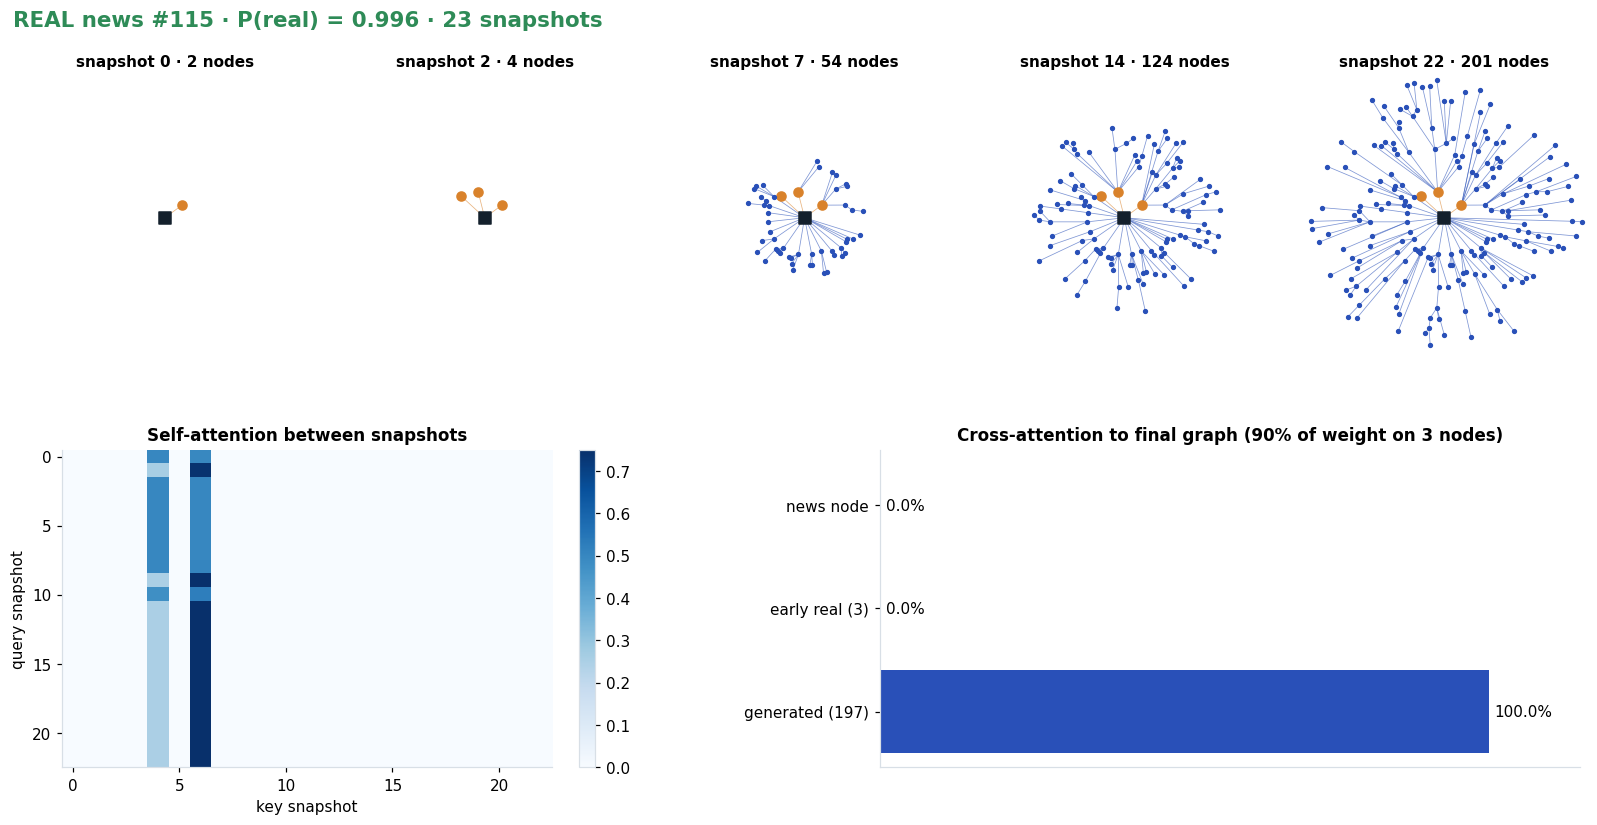

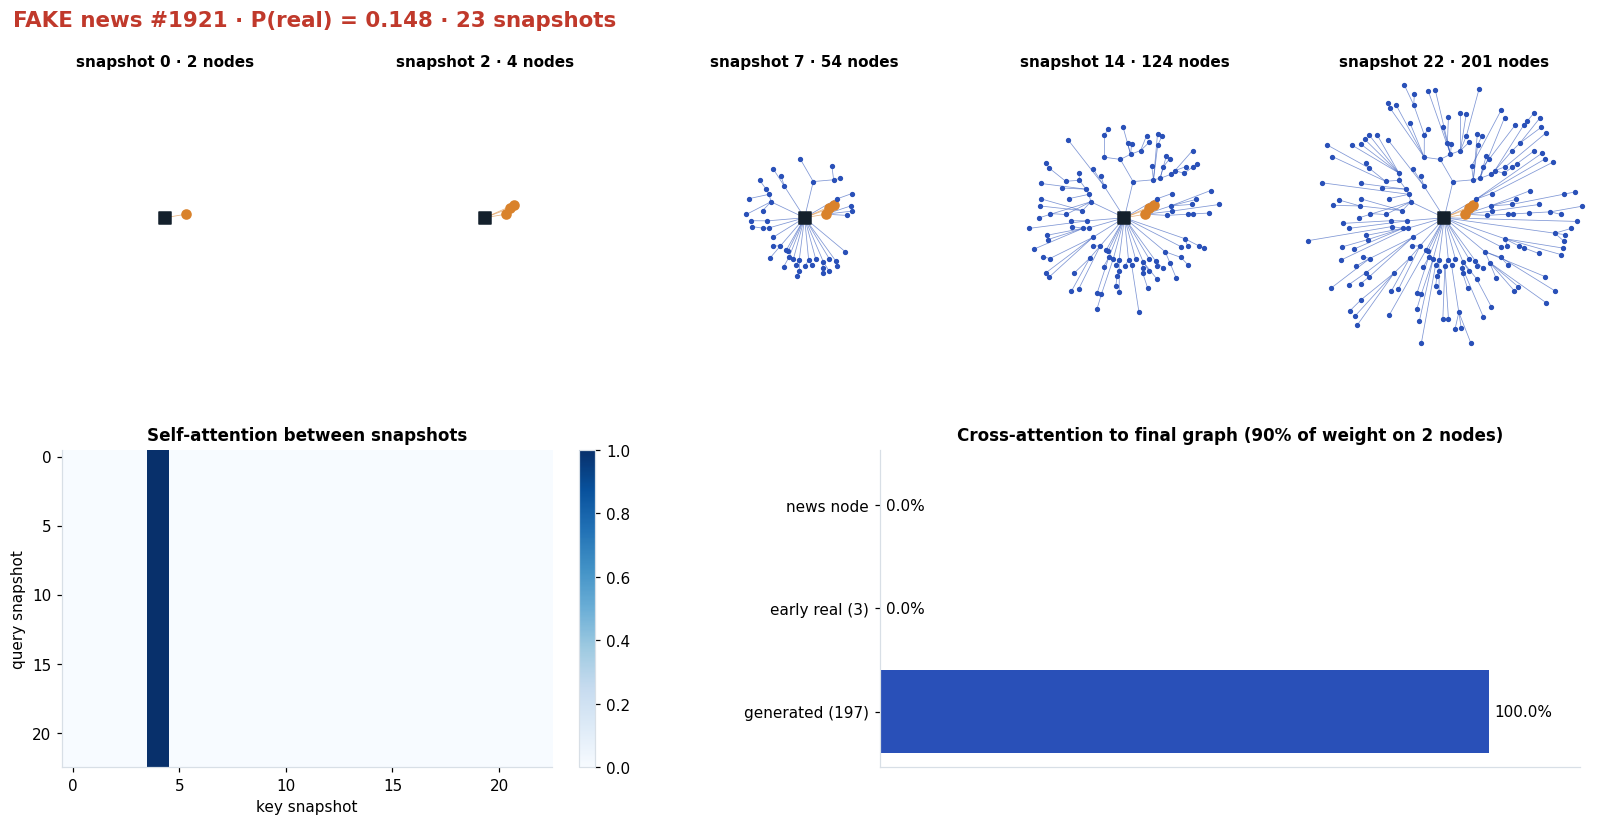

In [ ]:
OUT = {k: B.predict(k, explain=True) for k in PAIR}
for k in PAIR:
    viz.plot_snapshots(B, OUT[k])

**อะไรตัดสินผล?** ชั้นสุดท้ายเป็นสมการเส้นตรง จึงแยก logit ได้พอดีว่ามาจากเส้นทาง (h*), ข้อความ, ภาพ หรือค่าคงที่
และลองให้ detector ตัวเดิมเห็น G′ แค่ 0 ถึง 20 step ว่าผลของข่าว REAL / FAKE เปลี่ยนไหม

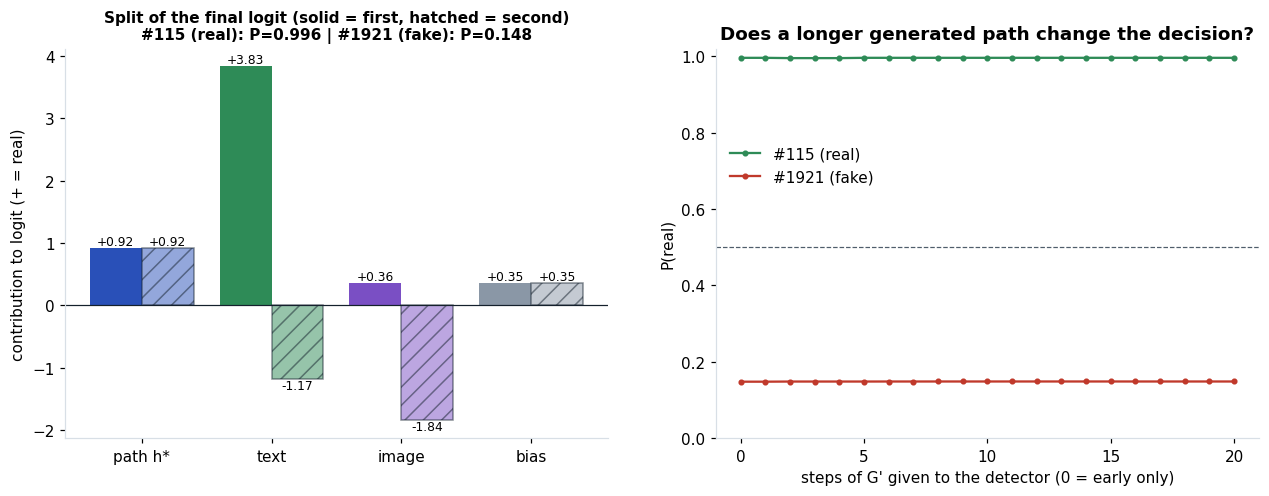

In [ ]:
name = {k: f"#{k} ({B.item(k)['label']})" for k in PAIR}
curves = {name[k]: [B.predict(k, n_steps=n) for n in range(len(B.stored_steps(k)) + 1)] for k in PAIR}
viz.plot_decision(B, {name[k]: OUT[k] for k in PAIR}, curves)

In [ ]:
# ทั้ง test set: ถ้าแทนส่วนของเส้นทางด้วยค่าเฉลี่ย accuracy เปลี่ยนเท่าไร (= model ใช้เส้นทางมากแค่ไหน)
parts = [B.predict(i, explain=True)['parts'] for i in test]
g = np.array([p['path h*'] for p in parts]); rest = np.array([p['text'] + p['image'] + p['bias'] for p in parts])
y = B.labels[test]
print(f'std of path term {g.std():.4f} · std of text+image {rest.std():.3f}')
print(f'acc {((g + rest > 0) == y).mean():.3f} -> with path term = constant {((g.mean() + rest > 0) == y).mean():.3f}')

std of path term 0.0003 · std of text+image 2.439
acc 0.823 -> with path term = constant 0.823


#### 🔧 Code ที่ใช้รันจริง · Temporal-aware Fake News Detection

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

**`src/data/rppg_datamodule.py`** · ตัดเส้นทาง (early จริง + G′) เป็น snapshot ให้ detector

In [ ]:
%%writefile code_used/src/data/rppg_datamodule.py
"""DataModule for Stage 2 (temporal-aware detection).

Each news item becomes a sequence of cumulative propagation snapshots G_0 ... G_T:
  * real part   - the real engagements available in this setting, split into ``real_slots`` steps
                  ("early": the 3-5 earliest engagements, as in Table III; "full": the whole cascade, as in
                  Table II, capped at ``max_real_users`` earliest users)
  * generated   - the steps of the path G' produced by Stage 1 (``src/train_hete_RL.py``)
Training news use ``train_real`` and validation / test news use ``eval_real`` (the paper simulates the
early stage on the test set only, Sec. IV-B).
"""
from __future__ import annotations

import os
from typing import Dict, List, Optional

import numpy as np
import torch
import torch.nn.functional as F
from lightning import LightningDataModule
from torch.utils.data import DataLoader, Dataset

from src.data.components.encode_content import cached as content_features
from src.data.components.politifact import NEWS_ROOT, build


def make_sample(eng, early, gen_steps, mode: str, real_slots: int, max_real_users: int, use_generated: bool,
                max_gen_users: Optional[int] = None, unk: Optional[set] = None):
    users: List[int] = []
    index: Dict[int, int] = {}
    edges: List[tuple] = []

    def add(u, parent):
        if u in index or u == NEWS_ROOT:
            return
        index[u] = len(users) + 1
        users.append(u)
        edges.append((index.get(parent, 0), index[u]))

    real = early if mode == "early" else eng
    for h, u, _ in real:
        if len(users) >= max_real_users:
            break
        add(u, -1 if h == NEWS_ROOT else h)
    n_real = len(users)
    bounds = []
    if n_real:
        for chunk in np.array_split(np.arange(1, n_real + 1), min(real_slots, n_real)):
            bounds.append(int(chunk[-1]) + 1)  # number of local nodes (seed included) in this snapshot
    else:
        bounds.append(1)
    if use_generated:
        cap = n_real + max_gen_users if max_gen_users is not None else None  # diagnostic, not in paper
        for step in gen_steps:
            before = len(users)
            for p, c in step:
                if cap is not None and len(users) >= cap:
                    break
                add(c, p)
            if len(users) > before:
                bounds.append(len(users) + 1)
    out = {"users": users, "edges": edges, "bounds": bounds}
    if unk:  # these users keep their node but get the UNK feature (row 0 of the user table, a user not in H)
        out["feat"] = [0 if u in unk else u for u in users]
    return out


class NewsDataset(Dataset):
    def __init__(self, idx, samples, labels):
        self.idx, self.samples, self.labels = idx, samples, labels

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, k):
        i = self.idx[k]
        return i, self.samples[i], self.labels[i]


class Collate:
    def __init__(self, user_emb: torch.Tensor, content: torch.Tensor):
        self.user_emb, self.content = user_emb, content

    def _graphs(self, items, temporal: bool):
        xs, seed_of, eis, gid, news_of, step_of = [], [], [], [], [], []
        off, g = 0, 0
        for b, (_, s, _) in enumerate(items):
            users = torch.tensor(s.get("feat", s["users"]), dtype=torch.long)
            e = torch.tensor(s["edges"], dtype=torch.long).reshape(-1, 2)
            bounds = s["bounds"] if temporal else [len(s["users"]) + 1]
            for t, nb in enumerate(bounds):
                feat = torch.zeros(nb, self.user_emb.size(1))
                if nb > 1:
                    feat[1:] = self.user_emb[users[: nb - 1]]
                so = torch.full((nb,), -1, dtype=torch.long)
                so[0] = b
                ee = e[e[:, 1] < nb] if len(e) else e
                xs.append(feat), seed_of.append(so), eis.append(ee.T + off)
                gid.append(torch.full((nb,), g, dtype=torch.long))
                news_of.append(b), step_of.append(t)
                off += nb
                g += 1
        return {"x": torch.cat(xs), "seed_of": torch.cat(seed_of), "edge_index": torch.cat(eis, 1),
                "batch": torch.cat(gid), "num_graphs": g, "news": torch.tensor(news_of), "step": torch.tensor(step_of)}

    def __call__(self, items):
        idx = torch.tensor([i for i, _, _ in items])
        return {"idx": idx, "content": self.content[idx], "y": torch.tensor([float(y) for _, _, y in items]),
                "temporal": self._graphs(items, True), "structure": self._graphs(items, False)}


class RPPGDataModule(LightningDataModule):
    def __init__(self, raw_dir: str = "data/politifact", processed_dir: str = "data/politifact/processed",
                 generated_dir: str = "data/politifact/generated", image_dir: Optional[str] = None, seed: int = 0,
                 n_slots: int = 20, slot_mode: str = "time", slot_users: int = 200, batch_size: int = 16,
                 train_real: str = "early", eval_real: str = "early",
                 real_slots: int = 10, max_real_users: int = 500, use_generated: bool = True, num_workers: int = 0,
                 max_gen_users: Optional[int] = None, text_chunks: int = 1, unk_users: bool = True,
                 shuffle_train_labels: bool = False, shuffle_seed: int = 99):
        super().__init__()
        self.save_hyperparameters(logger=False)

    def setup(self, stage: Optional[str] = None):
        if getattr(self, "_ready", False):
            return
        hp = self.hparams
        path = build(hp.raw_dir, hp.processed_dir, hp.seed, n_slots=hp.n_slots, slot_mode=hp.slot_mode,
                     slot_users=hp.slot_users)
        data = torch.load(path, weights_only=False)
        feats = content_features(path, hp.image_dir, text_chunks=hp.text_chunks)
        self.content = torch.cat([F.normalize(feats["text"], dim=-1), F.normalize(feats["image"], dim=-1)], -1)
        gen_path = os.path.join(hp.generated_dir, f"seed{hp.seed}", "stage1.pt")
        if not os.path.exists(gen_path):
            raise FileNotFoundError(f"{gen_path} not found - run Stage 1 first: python src/train_hete_RL.py seed={hp.seed}")
        gen = torch.load(gen_path, weights_only=False)
        assert gen["split"] == data["split"], "Stage 1 and Stage 2 must use the same seed / split"
        self.user_emb = gen["user_emb"].float()
        labels = data["labels"].tolist()
        if hp.shuffle_train_labels:  # leakage control only: permute TRAIN labels; val / test keep the true labels
            import random as _r
            tr_idx = list(data["split"]["train"])
            perm = [labels[i] for i in tr_idx]
            _r.Random(hp.seed + hp.shuffle_seed).shuffle(perm)
            for i, l in zip(tr_idx, perm):
                labels[i] = l
        split = data["split"]
        samples = {}
        solo = {}
        if hp.unk_users and "known" in gen:
            # leave-one-news-out: a train-news user whose only H edges come from that same news would be unknown
            # if the news were unseen, so it gets the UNK feature too (val/test unknown users already map to UNK)
            from collections import defaultdict
            seen = defaultdict(set)
            for i in split["train"]:
                for h, u, _ in data["eng"][i]:
                    seen[u].add(i)
                    if h != NEWS_ROOT:
                        seen[h].add(i)
            for i in split["train"]:
                solo[i] = {u for u, s in ((u, seen[u]) for _, u, _ in data["eng"][i]) if s == {i}}
        for name in ("train", "val", "test"):
            mode = hp.train_real if name == "train" else hp.eval_real
            for i in split[name]:
                samples[i] = make_sample(data["eng"][i], data["early"][i], gen["paths"][i]["steps"], mode,
                                         hp.real_slots, hp.max_real_users, hp.use_generated, hp.max_gen_users,
                                         solo.get(i))
        self.sets = {k: NewsDataset(split[k], samples, labels) for k in ("train", "val", "test")}
        self.collate = Collate(self.user_emb, self.content)
        self.content_dim, self.user_dim = self.content.size(1), self.user_emb.size(1)
        self._ready = True

    def _loader(self, name, shuffle):
        return DataLoader(self.sets[name], batch_size=self.hparams.batch_size, shuffle=shuffle,
                          num_workers=self.hparams.num_workers, collate_fn=self.collate)

    def train_dataloader(self):
        return self._loader("train", True)

    def val_dataloader(self):
        return self._loader("val", False)

    def test_dataloader(self):
        return self._loader("test", False)


**`src/models/components/rppg/detector.py`** · dynamic GAT + position (Eq. 20), fusion (Eq. 21), P(real) (Eq. 22)

In [ ]:
%%writefile code_used/src/models/components/rppg/detector.py
"""Module 3 - Temporal-aware fake news detection (Sec. III-D, Eqs. 20-22)."""
from __future__ import annotations

import torch
from torch import nn
from torch_geometric.utils import scatter, to_dense_batch

from src.models.components.rppg.layers import GATEncoder


class TemporalAwareDetector(nn.Module):
    """Dynamic propagation graph encoder + temporal-structure fusion + content.

    * Each snapshot G_t of the (real early + generated) path goes through a GAT; mean-pool readout gives
      h_t, and a temporal position embedding p_t is added: H^ = {h_0 + p_0, ..., h_T + p_T} (Eq. 20).
    * The final graph G_T goes through a second GAT -> structure features U^_T.
    * Fusion (Eq. 21):  H' = LN(SelfAttn(H^) + H^)
                        U  = LN(CrossAttn(query=H', key/value=U^_T) + H')
                        H* = LN(FeedForward(U) + H')
    * h* = mean-pool(H*);  P(y | n, G) = sigmoid(W_P [h* ; n] + b), n = [n_T ; n_V]  (Sec. III-D3).
    Returns the logit; the loss is binary cross-entropy (Eq. 22), with y = 1 for real news.
    """

    def __init__(self, user_dim: int = 128, content_dim: int = 1024, dim: int = 128, heads: int = 4,
                 dropout: float = 0.2, max_steps: int = 64):
        super().__init__()
        self.user_in = nn.Linear(user_dim, dim)
        self.seed_in = nn.Linear(content_dim, dim)       # the news seed node carries the content
        self.temporal_gat = GATEncoder(dim, dim, dim, heads, dropout)
        self.structure_gat = GATEncoder(dim, dim, dim, heads, dropout)
        self.pos = nn.Embedding(max_steps, dim)
        self.self_attn = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.ln1, self.ln2, self.ln3 = nn.LayerNorm(dim), nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.ffn = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * dim, dim))
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(dim + content_dim, 1)
        self.max_steps = max_steps

    def _nodes(self, g, content):
        h = self.user_in(g["x"])
        seed = g["seed_of"] >= 0
        if seed.any():
            h = h.clone()
            h[seed] = self.seed_in(content[g["seed_of"][seed]])
        return h

    def forward(self, batch):
        content = batch["content"]
        B = content.size(0)
        # ---- dynamic propagation graph encoder (Eq. 20)
        t = batch["temporal"]
        ht = self.temporal_gat(self._nodes(t, content), t["edge_index"])
        snap = scatter(ht, t["batch"], dim=0, dim_size=t["num_graphs"], reduce="mean")       # h_t per snapshot
        steps = t["step"].clamp(max=self.max_steps - 1)
        snap = snap + self.pos(steps)
        H, tmask = to_dense_batch(snap, t["news"], batch_size=B)                              # (B, L, d)
        # ---- structure features of the final graph
        s = batch["structure"]
        hs = self.structure_gat(self._nodes(s, content), s["edge_index"])
        S, smask = to_dense_batch(hs, s["batch"], batch_size=B)                               # (B, N, d)
        # ---- temporal-structure fusion (Eq. 21)
        a, _ = self.self_attn(H, H, H, key_padding_mask=~tmask)
        H1 = self.ln1(a + H)
        c, _ = self.cross_attn(H1, S, S, key_padding_mask=~smask)
        H2 = self.ln2(c + H1)
        H3 = self.ln3(self.ffn(H2) + H1)  # residual to H' as written in Eq. 21
        m = tmask.unsqueeze(-1).float()
        h_star = (H3 * m).sum(1) / m.sum(1).clamp_min(1.0)                                   # readout = mean pool
        return self.out(torch.cat([self.drop(h_star), content], -1)).squeeze(-1)


**`src/models/rppg_detector_module.py`** · loss BCE (Eq. 22) + metric (positive class = real)

In [ ]:
%%writefile code_used/src/models/rppg_detector_module.py
"""Lightning wrapper for Module 3 (temporal-aware detection)."""
from __future__ import annotations

from typing import Any

import torch
import torch.nn.functional as F
from lightning import LightningModule
from torchmetrics import MaxMetric, MeanMetric, MetricCollection
from torchmetrics.classification import (BinaryAccuracy, BinaryAUROC, BinaryF1Score, BinaryPrecision,
                                         BinaryRecall, MulticlassF1Score)

from src.models.components.rppg.detector import TemporalAwareDetector


def _metrics():
    # Positive class = 1 = real news (paper: y = 0 fake, y = 1 real); acc/pre/rec/f1 as in Tables II-IV.
    return MetricCollection({"acc": BinaryAccuracy(), "pre": BinaryPrecision(), "rec": BinaryRecall(),
                             "f1": BinaryF1Score(), "macro_f1": MulticlassF1Score(num_classes=2, average="macro")})


class RPPGDetectorModule(LightningModule):
    def __init__(self, user_dim: int = 128, content_dim: int = 1024, dim: int = 128, heads: int = 4,
                 dropout: float = 0.2, max_steps: int = 64, lr: float = 5e-3, weight_decay: float = 1e-2):
        super().__init__()
        self.save_hyperparameters()
        self.net = TemporalAwareDetector(user_dim, content_dim, dim, heads, dropout, max_steps)
        self.m = torch.nn.ModuleDict({k: _metrics() for k in ("tr", "va", "te")})
        self.auc = torch.nn.ModuleDict({k: BinaryAUROC() for k in ("va", "te")})
        self.loss_avg = torch.nn.ModuleDict({k: MeanMetric() for k in ("tr", "va", "te")})
        self.val_acc_best = MaxMetric()

    def forward(self, batch):
        return self.net(batch)

    def _step(self, batch, key):
        logit = self(batch)
        y = batch["y"]
        loss = F.binary_cross_entropy_with_logits(logit, y)  # Eq. 22
        prob = torch.sigmoid(logit)
        pred = (prob > 0.5).long()
        yl = y.long()
        self.loss_avg[key](loss)
        for name, metric in self.m[key].items():
            metric.update(pred if name == "macro_f1" else prob, yl)
        if key in self.auc:
            self.auc[key].update(prob, yl)
        return loss

    def _log_epoch(self, key, prefix):
        out = {f"{prefix}/{k}": v for k, v in self.m[key].compute().items()}
        out[f"{prefix}/loss"] = self.loss_avg[key].compute()
        if key in self.auc:
            out[f"{prefix}/auc"] = self.auc[key].compute()
            self.auc[key].reset()
        self.m[key].reset()
        self.loss_avg[key].reset()
        self.log_dict(out, prog_bar=prefix != "test")
        return out

    def on_train_start(self):
        # the sanity-check validation (2 batches) must not count as the best validation accuracy
        self.val_acc_best.reset()
        self.m["va"].reset(), self.auc["va"].reset(), self.loss_avg["va"].reset()

    def training_step(self, batch: Any, batch_idx: int):
        return self._step(batch, "tr")

    def on_train_epoch_end(self):
        self._log_epoch("tr", "train")

    def validation_step(self, batch: Any, batch_idx: int):
        self._step(batch, "va")

    def on_validation_epoch_end(self):
        out = self._log_epoch("va", "val")
        self.val_acc_best(out["val/acc"])
        self.log("val/acc_best", self.val_acc_best.compute(), prog_bar=True)

    def test_step(self, batch: Any, batch_idx: int):
        self._step(batch, "te")

    def on_test_epoch_end(self):
        self._log_epoch("te", "test")

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=self.hparams.lr, weight_decay=self.hparams.weight_decay)


**`src/train.py`** · Stage 2 = Algorithm 1 บรรทัด 15-17: train detector, เลือก checkpoint ด้วย val acc, วัด test

In [ ]:
%%writefile code_used/src/train.py
import json
import os
from typing import List, Optional, Tuple

import hydra
import lightning as L
import pyrootutils
import torch
from lightning import Callback, LightningDataModule, LightningModule, Trainer
from lightning.pytorch.loggers import Logger
from omegaconf import DictConfig

pyrootutils.setup_root(__file__, indicator=".project-root", pythonpath=True)
# ------------------------------------------------------------------------------------ #
# the setup_root above is equivalent to:
# - adding project root dir to PYTHONPATH
#       (so you don't need to force user to install project as a package)
#       (necessary before importing any local modules e.g. `from src import utils`)
# - setting up PROJECT_ROOT environment variable
#       (which is used as a base for paths in "configs/paths/default.yaml")
#       (this way all filepaths are the same no matter where you run the code)
# - loading environment variables from ".env" in root dir
#
# you can remove it if you:
# 1. either install project as a package or move entry files to project root dir
# 2. set `root_dir` to "." in "configs/paths/default.yaml"
#
# more info: https://github.com/ashleve/pyrootutils
# ------------------------------------------------------------------------------------ #

from src import utils

log = utils.get_pylogger(__name__)


@utils.task_wrapper
def train(cfg: DictConfig) -> Tuple[dict, dict]:
    """Trains the model. Can additionally evaluate on a testset, using best weights obtained during
    training.

    This method is wrapped in optional @task_wrapper decorator, that controls the behavior during
    failure. Useful for multiruns, saving info about the crash, etc.

    Args:
        cfg (DictConfig): Configuration composed by Hydra.

    Returns:
        Tuple[dict, dict]: Dict with metrics and dict with all instantiated objects.
    """

    # set seed for random number generators in pytorch, numpy and python.random
    if cfg.get("seed") is not None:
        L.seed_everything(cfg.seed, workers=True)

    log.info(f"Instantiating datamodule <{cfg.data._target_}>")
    datamodule: LightningDataModule = hydra.utils.instantiate(cfg.data)

    log.info(f"Instantiating model <{cfg.model._target_}>")
    model: LightningModule = hydra.utils.instantiate(cfg.model)

    log.info("Instantiating callbacks...")
    callbacks: List[Callback] = utils.instantiate_callbacks(cfg.get("callbacks"))

    log.info("Instantiating loggers...")
    logger: List[Logger] = utils.instantiate_loggers(cfg.get("logger"))

    log.info(f"Instantiating trainer <{cfg.trainer._target_}>")
    trainer: Trainer = hydra.utils.instantiate(cfg.trainer, callbacks=callbacks, logger=logger)

    object_dict = {
        "cfg": cfg,
        "datamodule": datamodule,
        "model": model,
        "callbacks": callbacks,
        "logger": logger,
        "trainer": trainer,
    }

    if logger:
        log.info("Logging hyperparameters!")
        utils.log_hyperparameters(object_dict)

    if cfg.get("compile"):
        log.info("Compiling model!")
        model = torch.compile(model)

    if cfg.get("train"):
        log.info("Starting training!")
        trainer.fit(model=model, datamodule=datamodule, ckpt_path=cfg.get("ckpt_path"))

    train_metrics = trainer.callback_metrics

    if cfg.get("test"):
        log.info("Starting testing!")
        ckpt_path = trainer.checkpoint_callback.best_model_path
        if ckpt_path == "":
            log.warning("Best ckpt not found! Using current weights for testing...")
            ckpt_path = None
        trainer.test(model=model, datamodule=datamodule, ckpt_path=ckpt_path)
        log.info(f"Best ckpt path: {ckpt_path}")

    test_metrics = trainer.callback_metrics

    # merge train and test metrics
    metric_dict = {**train_metrics, **test_metrics}

    # keep a small JSON per run so several seeds can be aggregated (scripts/run_all.py)
    summary = {k: float(v) for k, v in metric_dict.items() if k.startswith("test/") or k == "val/acc_best"}
    summary.update({"seed": cfg.seed, "dataset": cfg.get("dataset"), "tag": cfg.get("tag"), "train_real": cfg.data.get("train_real"), "eval_real": cfg.data.get("eval_real"), "use_generated": cfg.data.get("use_generated"),
                    "best_ckpt": ckpt_path if cfg.get("test") else None})
    with open(os.path.join(cfg.paths.output_dir, "test_metrics.json"), "w") as f:
        json.dump(summary, f, indent=2)

    return metric_dict, object_dict


@hydra.main(version_base="1.3", config_path="../configs", config_name="train_detection_graph.yaml")
def main(cfg: DictConfig) -> Optional[float]:
    # apply extra utilities
    # (e.g. ask for tags if none are provided in cfg, print cfg tree, etc.)
    """
    cfg : train/text.yaml to dic, every children yaml is the same dic structure
    e.g cfg={"task_name":"train,"data":{"_target_":"xxx","data_dir":"xxx"}}
    """
    
    utils.extras(cfg)

    # train the model
    metric_dict, _ = train(cfg)

    # safely retrieve metric value for hydra-based hyperparameter optimization
    metric_value = utils.get_metric_value(
        metric_dict=metric_dict, metric_name=cfg.get("optimized_metric")
    )

    # return optimized metric
    return metric_value


if __name__ == "__main__":
    main()


## 5. ผลบน test set (แยกข่าว real / fake)

test 402 news (282 real / 120 fake) · acc 0.823 · F1 0.879 · AUC 0.906
   real news predicted correctly 91.1% · fake news predicted correctly 61.7%


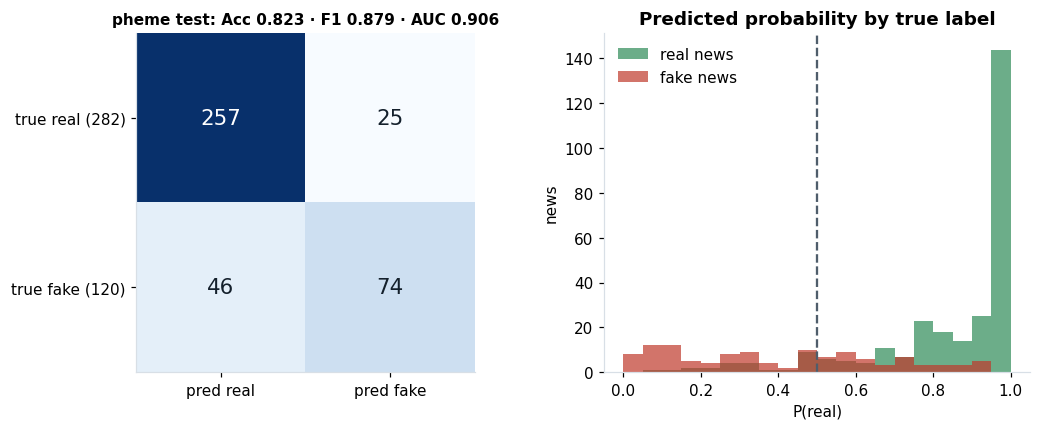

In [ ]:
RES = {'test': B.evaluate('test')}
r = RES['test']
print(f"test {r['n']} news ({r['real']} real / {r['fake']} fake) · acc {r['acc']:.3f} · F1 {r['f1']:.3f} · AUC {r['auc']:.3f}")
print(f"   real news predicted correctly {r['acc_real']:.1%} · fake news predicted correctly {r['acc_fake']:.1%}")
viz.plot_evaluation(r, f'{DATASET} test')

#### 🔧 Code ที่ใช้รันจริง · รันทุก seed และสรุปผล

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

**`scripts/run_all.py`** · รัน Stage 1 + 2 ทุก seed / setting แล้วสรุป mean ± std

In [ ]:
%%writefile code_used/scripts/run_all.py
"""Run the full RPPG-Fake pipeline for several seeds and report mean +/- std (paper: 5 runs, Sec. IV-B).

    python scripts/run_all.py --seeds 0 1 2 3 4                 # Stage 1 + Stage 2 (early + full)
    python scripts/run_all.py --seeds 0 1 2 3 4 --skip_stage1   # reuse existing Stage 1 outputs
    python scripts/run_all.py --aggregate_only                  # just rebuild the results table

Each seed uses its own stratified 7:1:2 split. Results go to logs/results_<setting>.csv and
logs/results_summary.md.
"""
from __future__ import annotations

import argparse
import glob
import json
import os
import statistics
import subprocess
import sys

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
PY = sys.executable
SETTINGS = {
    "early": ["data.train_real=early", "data.eval_real=early"],                                # Table III
    "full": ["data.train_real=full", "data.eval_real=full"],                                   # Table II
    "early_no_gen": ["data.train_real=early", "data.eval_real=early", "data.use_generated=false"],  # ablation
}
METRICS = ["test/acc", "test/pre", "test/rec", "test/f1", "test/macro_f1", "test/auc"]


def run(cmd):
    print(">>", " ".join(cmd), flush=True)
    subprocess.run(cmd, cwd=ROOT, check=True)


def latest_metrics(tag: str, dataset: str):
    rows = []
    for p in glob.glob(os.path.join(ROOT, "logs", "stage2_detect", "runs", "*", "test_metrics.json")):
        with open(p) as f:
            m = json.load(f)
        if m.get("tag") == tag and m.get("dataset", "politifact") == dataset:
            rows.append((os.path.getmtime(p), m))
    best = {}
    for _, m in sorted(rows, key=lambda r: r[0]):
        best[m["seed"]] = m  # keep the newest run per seed
    return [best[s] for s in sorted(best)]


def aggregate(settings, dataset):
    lines = ["| Setting | n | " + " | ".join(m.split("/")[1] for m in METRICS) + " |",
             "|---|---|" + "---|" * len(METRICS)]
    for name in settings:
        rows = latest_metrics(name, dataset)
        if not rows:
            continue
        with open(os.path.join(ROOT, "logs", f"results_{dataset}_{name}.csv"), "w") as f:
            f.write("seed," + ",".join(METRICS) + "\n")
            for r in rows:
                f.write(f"{r['seed']}," + ",".join(f"{r.get(m, float('nan')):.4f}" for m in METRICS) + "\n")
        cells = []
        for m in METRICS:
            v = [r[m] for r in rows if m in r]
            sd = statistics.stdev(v) if len(v) > 1 else 0.0
            cells.append(f"{statistics.mean(v):.3f} ± {sd:.3f}")
        lines.append(f"| {name} | {len(rows)} | " + " | ".join(cells) + " |")
    table = "\n".join(lines)
    with open(os.path.join(ROOT, "logs", f"results_summary_{dataset}.md"), "w", encoding="utf-8") as f:
        f.write(f"# RPPG-Fake reproduction on {dataset} (mean ± std over seeds)\n\n" + table + "\n")
    print(table)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", default="politifact")
    ap.add_argument("--seeds", type=int, nargs="+", default=[0, 1, 2, 3, 4])
    ap.add_argument("--settings", nargs="+", default=list(SETTINGS))
    ap.add_argument("--skip_stage1", action="store_true")
    ap.add_argument("--aggregate_only", action="store_true")
    ap.add_argument("--extra", nargs="*", default=[], help="extra Hydra overrides for Stage 2")
    ap.add_argument("--stage1_extra", nargs="*", default=[], help="extra Hydra overrides for Stage 1")
    ap.add_argument("--tag_suffix", default="", help="appended to the setting names, e.g. _mm for text+image runs")
    ap.add_argument("--gen_name", default="generated", help="folder under data/<dataset>/ for Stage 1 output")
    a = ap.parse_args()
    gen_root = os.path.join(ROOT, "data", a.dataset, a.gen_name).replace("\\", "/")
    if not a.aggregate_only:
        for s in a.seeds:
            if not a.skip_stage1 or not os.path.exists(os.path.join(gen_root, f"seed{s}", "stage1.pt")):
                run([PY, "src/train_hete_RL.py", f"seed={s}", f"dataset={a.dataset}", "extras.print_config=False",
                     f"output_dir={gen_root}/seed{s}", *a.stage1_extra])
            for name in a.settings:
                run([PY, "src/train.py", f"seed={s}", f"dataset={a.dataset}", "extras.print_config=False",
                     "callbacks.rich_progress_bar=null", f"+tag={name}{a.tag_suffix}", f"data.generated_dir={gen_root}",
                     *SETTINGS[name], *a.extra])
    aggregate([n + a.tag_suffix for n in a.settings], a.dataset)


if __name__ == "__main__":
    main()


**`logs/run_fix.sh`** · คำสั่งที่ใช้จริงในรอบ 8 (ผลที่นำเสนอ)

In [ ]:
%%writefile code_used/logs/run_fix.sh
#!/bin/bash
# Round 8 - retrain after the embedding-collapse fixes (2026-10-19), paper settings except RL 5 epochs (paper gives no
# epoch count; user chose 5 to save time). Seeds 0-2, one job at a time (RAM). Tag *_fix, Stage 1 in generated_fix.
#   fixes: contrastive.pos_neg=structure, generator.standardize=true (both defaults in configs/train_Hete_RL.yaml)
declare -A TC=([pheme]=1 [politifact]=8 [gossipcop]=1)
cd "$(dirname "$0")/.."
for ds in pheme gossipcop politifact; do
  .venv/Scripts/python -u scripts/run_all.py --dataset $ds --seeds 0 1 2 --skip_stage1 \
    --gen_name generated_fix --tag_suffix _fix \
    --stage1_extra data.text_chunks=${TC[$ds]} generator.epochs=5 --extra data.text_chunks=${TC[$ds]} || echo "FAILED $ds fix"
done
echo "FIX ALL DONE"


## 6. ข้อมูลจากแหล่งอื่น: เหตุการณ์ที่ model ไม่เคยเห็น

PHEME รุ่น 9 เหตุการณ์ (figshare 6392078, CC BY 4.0) มี 4 เหตุการณ์ที่ไม่อยู่ใน training: ebola-essien, gurlitt, prince-toronto, putinmissing
เราเก็บเฉพาะข่าวที่มีครบ ข้อความ + ภาพ + เส้นทาง ได้ 64 ข่าว · user ที่ model ไม่รู้จักใช้เวกเตอร์ UNK
ทุกอย่างเหมือนส่วนที่ 1-5 (CLIP feature และ G′ คำนวณไว้แล้วด้วย model ตัวเดียวกัน) · มีเฉพาะ DATASET = 'pheme'

PHEME 9 events (figshare 6392078, CC BY 4.0): events ebola-essien, gurlitt, prince-toronto, putinmissing, which are not in the training data; only threads with text + image + path


news  correct  early_users_in_H
event          label                                 
ebola-essien   fake      3        0              0.00
gurlitt        real      2        1              0.12
prince-toronto fake     33        0              0.16
putinmissing   fake     11        0              0.27
               real     15       15              0.06

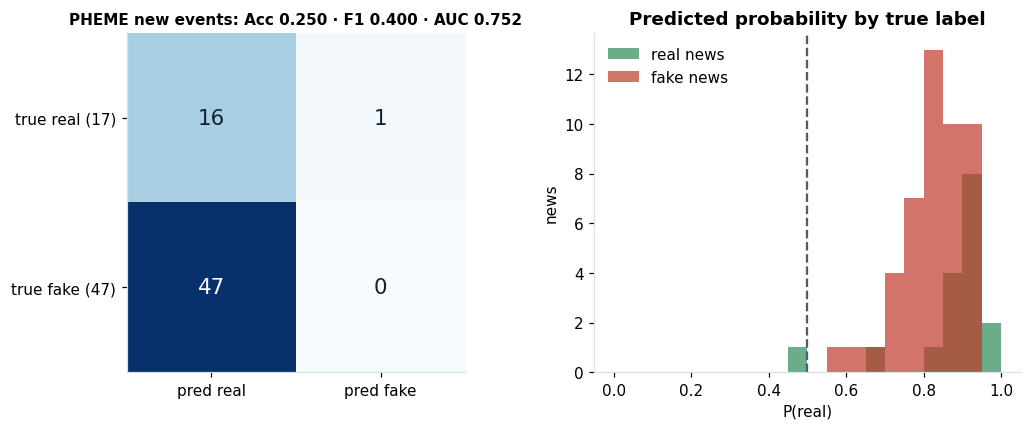

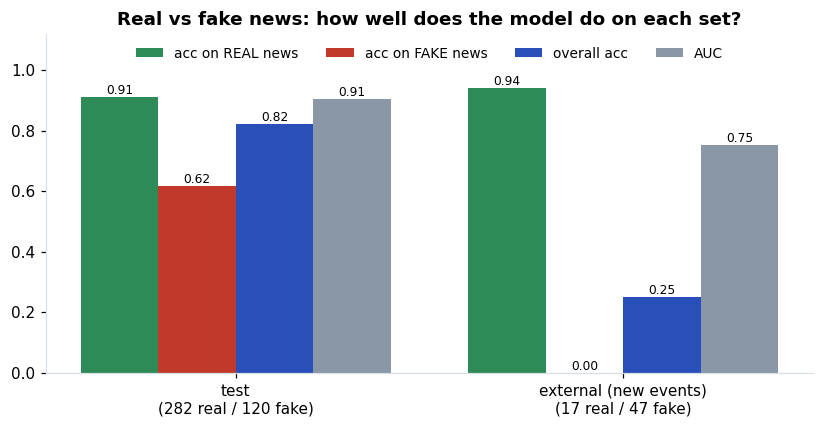

In [ ]:
EXT_PAIR = []
if B.ext is None:
    print('ไม่มีข้อมูลจากแหล่งอื่นสำหรับ', DATASET, '-> ข้ามส่วนนี้ (ใช้ DATASET = "pheme")')
else:
    print(B.ext['source'])
    ext = pd.DataFrame([{'key': k, 'event': B.item(k)['event'], 'label': B.item(k)['label'], 'P(real)': round(B.predict(k), 3),
                         'early users in H': B.known_share(k)} for k in B.ext_keys()])
    ext['pred'] = np.where(ext['P(real)'] > 0.5, 'real', 'fake')
    ext['correct'] = ext['pred'] == ext['label']
    display(ext.groupby(['event', 'label']).agg(news=('key', 'size'), correct=('correct', 'sum'),
                                                early_users_in_H=('early users in H', 'mean')).round(2))
    RES['external (new events)'] = B.evaluate('external')
    viz.plot_evaluation(RES['external (new events)'], 'PHEME new events')
    viz.plot_compare_sets(RES)

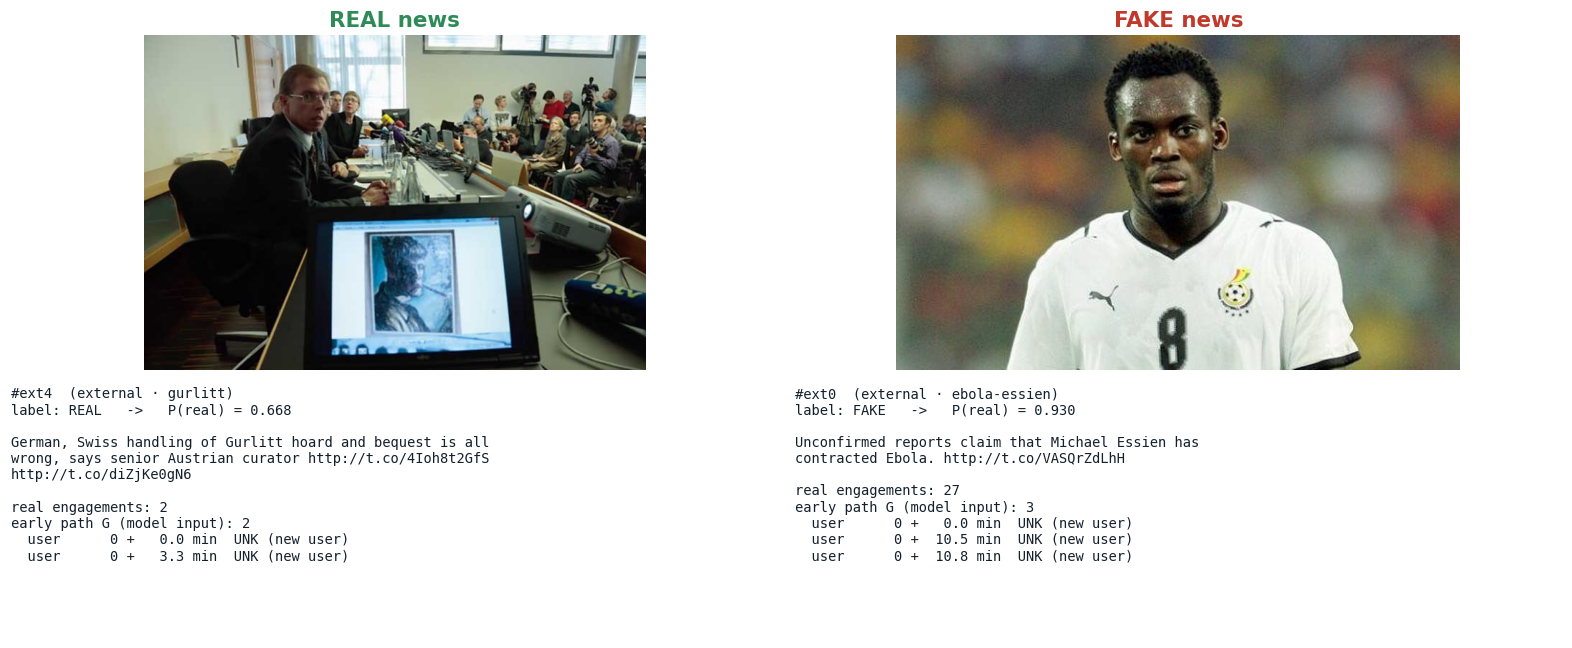

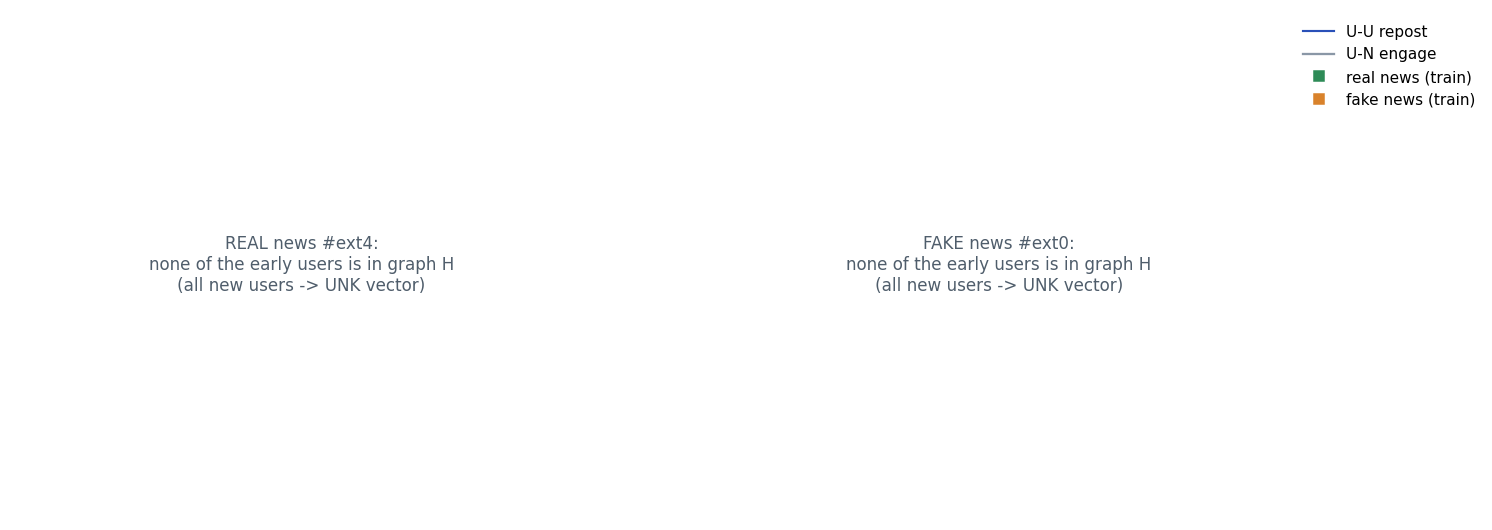

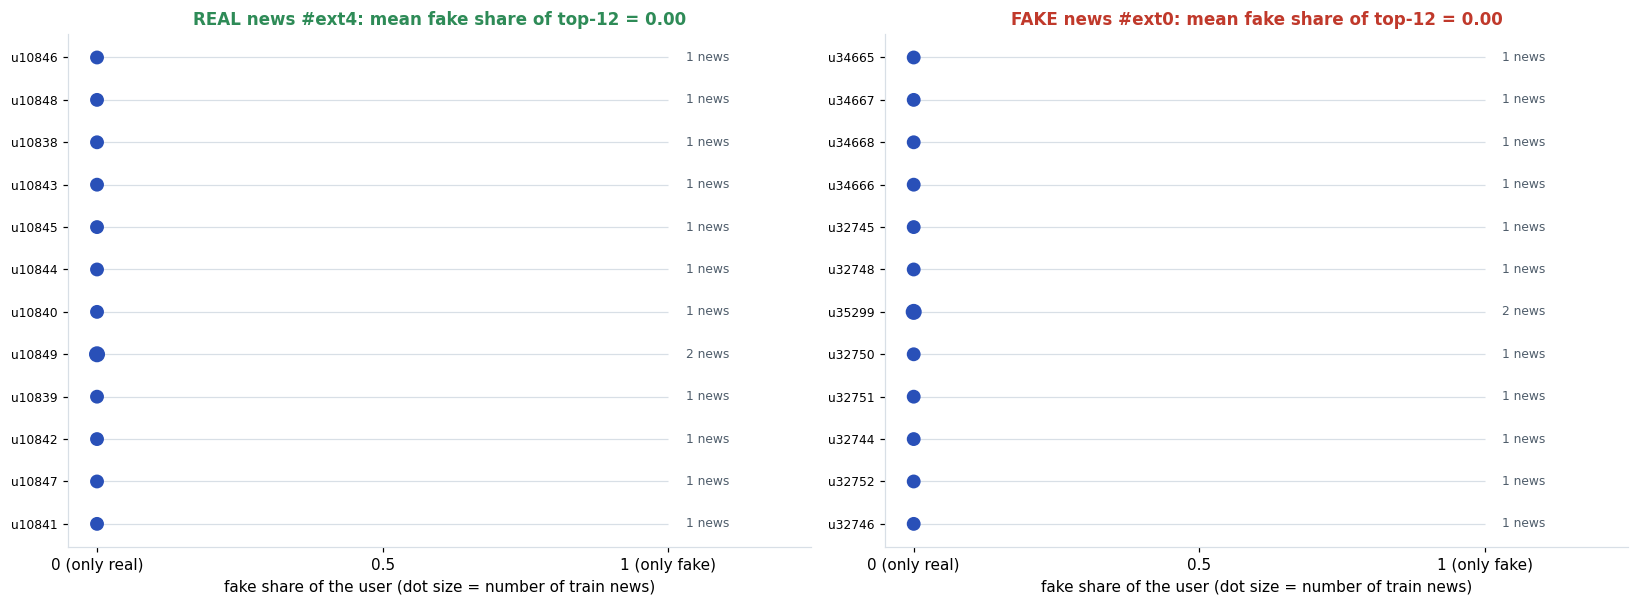

In [ ]:
# คู่ REAL / FAKE จากเหตุการณ์ใหม่: ผ่านทุก module เหมือนข้างบน
if B.ext is not None:
    # ข่าว real ส่วนใหญ่ทายถูก (16 / 17) จึงเลือกข่าว real ที่ทายถูก · ข่าว fake ทุกข่าวถูกทายผิดเป็น real
    EXT_REAL = next(k for k in B.ext_keys() if B.label(k) == 1 and B.predict(k) > 0.5)
    EXT_FAKE = next(k for k in B.ext_keys() if B.label(k) == 0)
    EXT_PAIR = [EXT_REAL, EXT_FAKE]
    viz.show_pair(B, EXT_PAIR, [B.predict(k) for k in EXT_PAIR])
    viz.plot_ego_pair(B, EXT_PAIR)
    viz.plot_content_candidates_pair(B, EXT_PAIR, k=12)

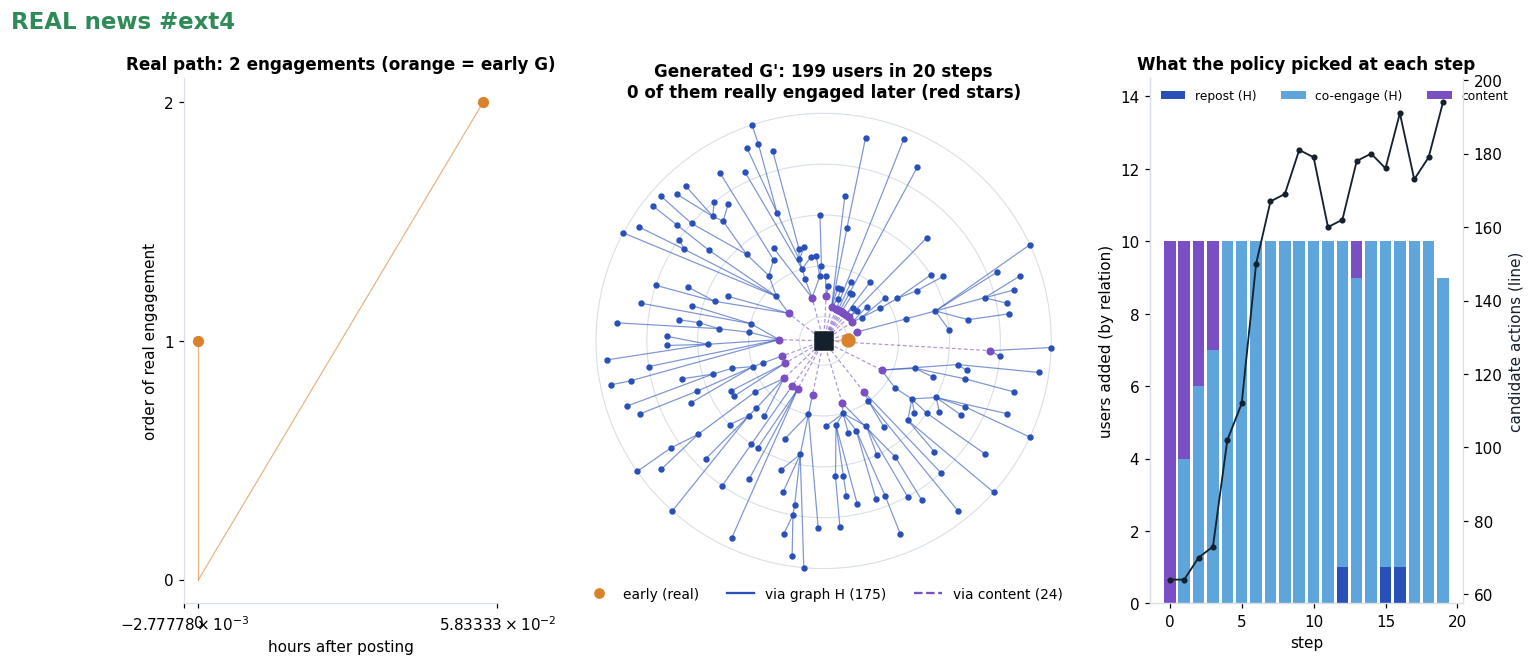

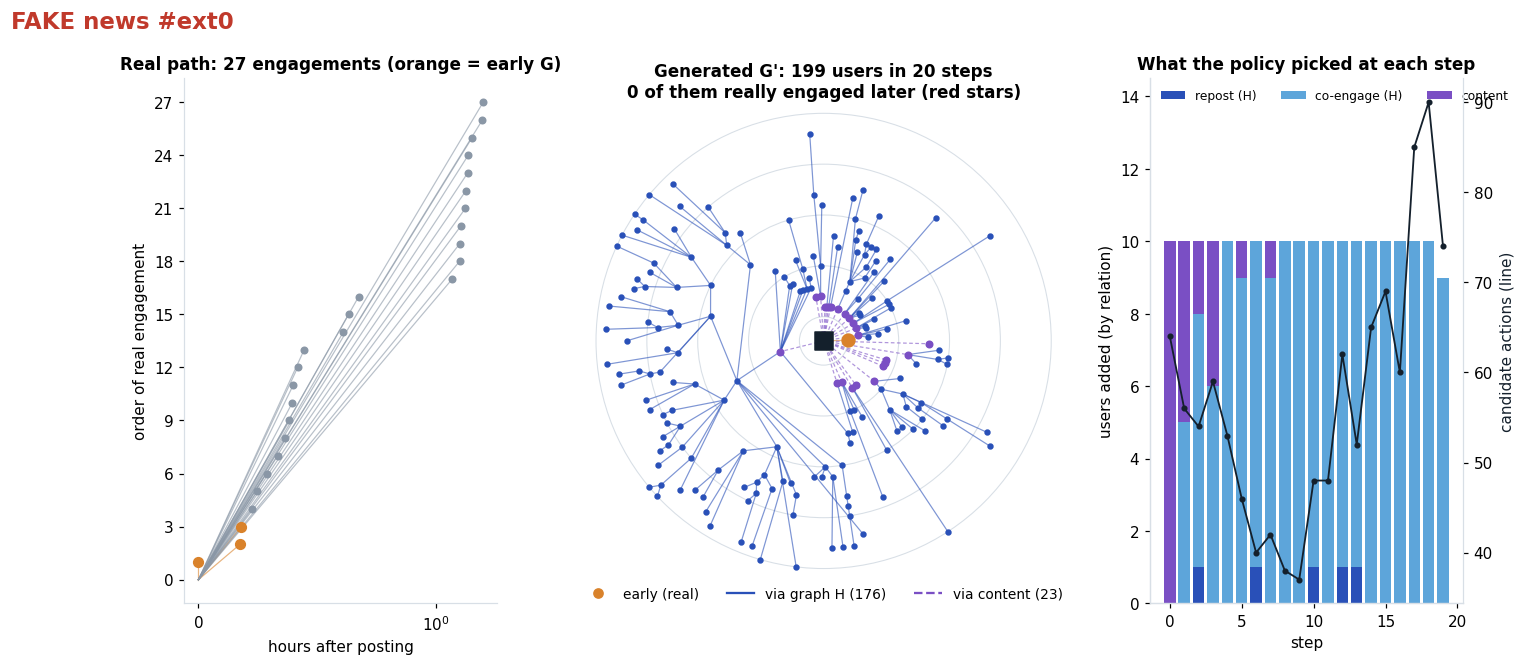

news,#ext4 REAL,#ext0 FAKE
early users in H,0%,0%
generated users,199,199
via graph H,175,176
via content,24,23
match real later users,0,0
mean candidates / step,146.2,57.1
mean entropy of π,4.86,3.85


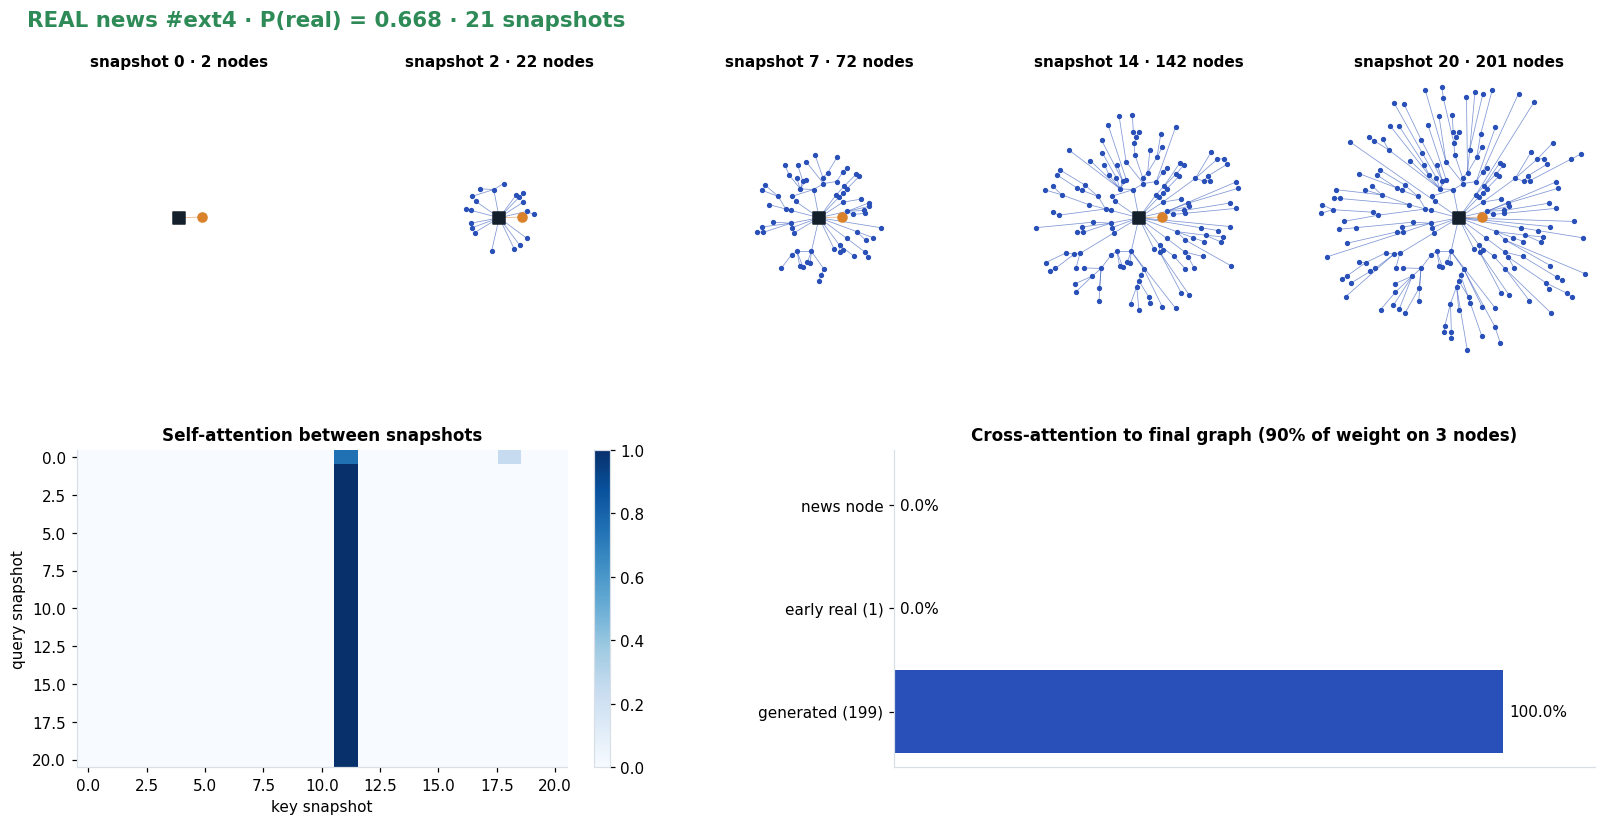

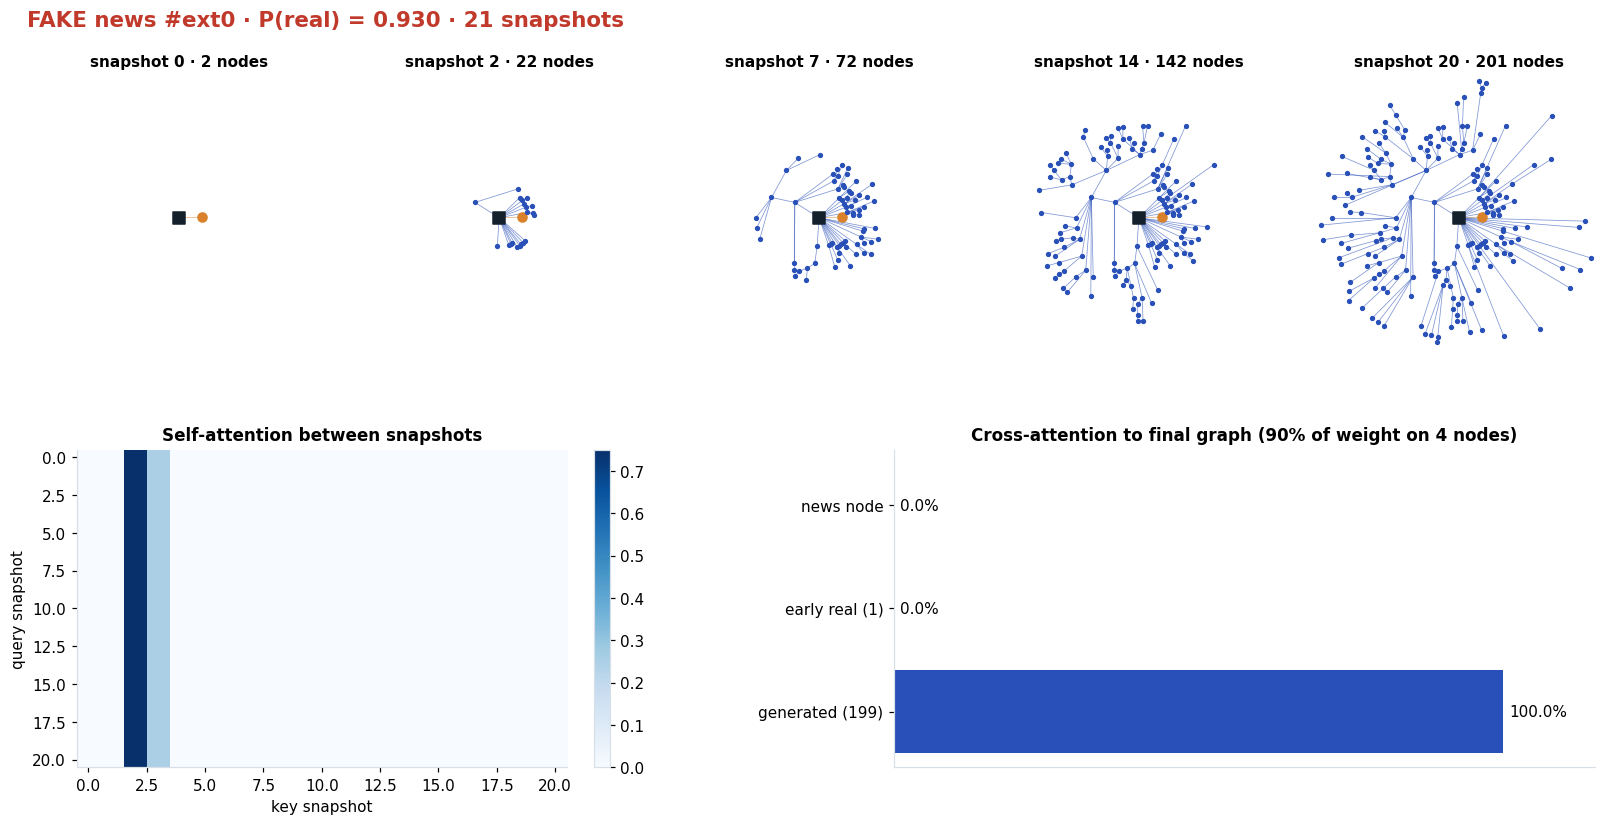

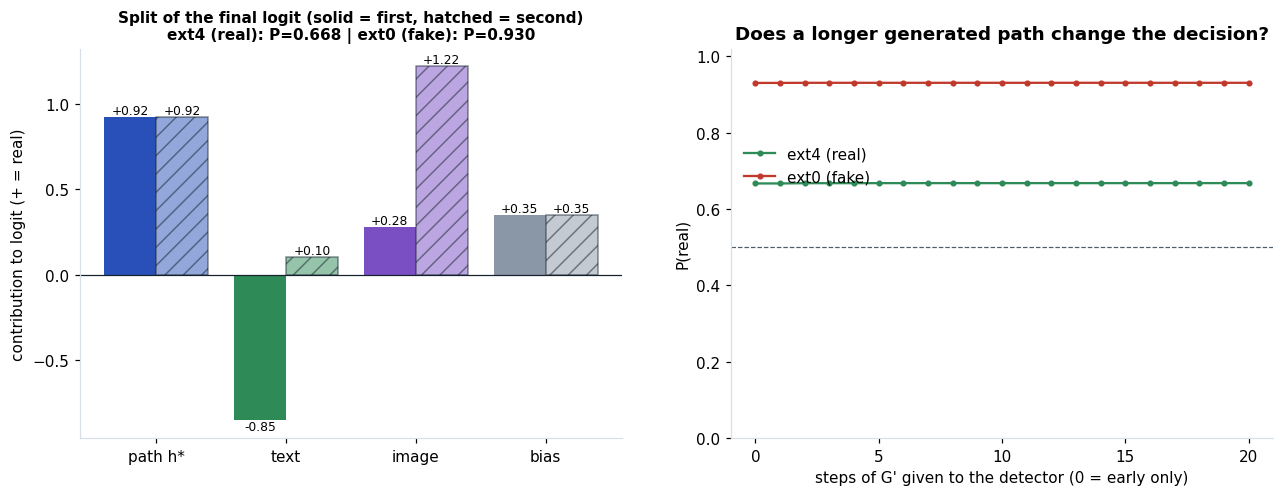

In [ ]:
if B.ext is not None:
    for k in EXT_PAIR:
        GEN[k] = B.generate(k, seed=0)
        viz.plot_generation(B, k, *GEN[k])
    display(pd.DataFrame([gen_summary(k, *GEN[k]) for k in EXT_PAIR]).set_index('news').T)
    name.update({k: f"{k} ({B.item(k)['label']})" for k in EXT_PAIR})
    for k in EXT_PAIR:
        OUT[k] = B.predict(k, explain=True)
        viz.plot_snapshots(B, OUT[k])
    viz.plot_decision(B, {name[k]: OUT[k] for k in EXT_PAIR},
                      {name[k]: [B.predict(k, n_steps=n) for n in range(len(B.stored_steps(k)) + 1)] for k in EXT_PAIR})

**ทำไมเหตุการณ์ใหม่ทายไม่ได้:** user ช่วงแรกส่วนใหญ่ไม่อยู่ในกราฟ H (ได้เวกเตอร์ UNK เหมือนกันหมด) · เนื้อหาเป็นเรื่องใหม่ ·
สัดส่วน fake สูงกว่าตอน train มาก · AUC ยังสูงกว่า 0.5 แปลว่าคะแนนข่าว fake ต่ำกว่าข่าว real โดยเฉลี่ย แต่ threshold 0.5 ใช้ไม่ได้
(เราไม่ปรับ threshold หลังเห็นผล เพราะจะเป็นการปรับบนข้อมูลทดสอบ)

#### 🔧 Code ที่ใช้รันจริง · ทำนายข่าวที่ model ไม่เคยเห็น

ไฟล์จริงจาก `Paper-Based/Code_RPPG-Fake/` ที่ใช้ train model รอบ 8 · cell ด้านล่างทำหน้าที่แสดง code (รัน cell = เขียนไฟล์ลง `code_used/` ไม่กระทบ demo ด้านบน ซึ่งใช้ `rppg_demo/` ที่คัดลอกจาก code ชุดนี้)

**`scripts/predict.py`** · สิ่งที่ใช้สร้างผลส่วนนี้ (และ Demo A / B / C)

In [ ]:
%%writefile code_used/scripts/predict.py
"""Run a trained RPPG-Fake model on news it has never seen (inference / demo, Algorithm 1 at test time).

    python scripts/predict.py --dataset pheme --input data/pheme_demo --tag early_final
    python scripts/predict.py --dataset pheme --input data/pheme_demo --tag early_final --seed 1

Input folder (same format as training): ``news_actions_<name>.csv`` (id, text, label?, actions_id[, event]),
``images/<id>.jpg`` and ``user_id_map.json`` built with the training map, so users seen in training keep their
id; users the model has never seen (id >= number of training users) are mapped to the unused id 0.

For every news item: early-stage engagements (3-5 earliest, Sec. IV-B) -> CLIP content n = [n_T ; n_V] ->
generated path G' from the trained generator (Module 2, on the training graph H) -> temporal-aware detector
(Module 3) -> P(real). Without ``--seed`` the seed with the best *validation* accuracy is used.
Output: ``logs/predict_<input>_<tag>_seed<k>.csv`` (+ ``.json`` with metrics when labels are given).
"""
from __future__ import annotations

import argparse
import csv
import glob
import json
import os
import random
import sys

import numpy as np
import torch
import torch.nn.functional as F
from omegaconf import OmegaConf

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
sys.path.insert(0, ROOT)
from src.data.components.encode_content import encode  # noqa: E402
from src.data.components.politifact import NEWS_ROOT, early_engagements, load_news  # noqa: E402
from src.data.rppg_datamodule import Collate, make_sample  # noqa: E402
from src.models.components.rppg.contrastive import HeteroGraphContrastive  # noqa: E402
from src.models.components.rppg.generator import PropagationEnv, RPPGGenerator, rollout  # noqa: E402
from src.models.rppg_detector_module import RPPGDetectorModule  # noqa: E402
from src.train_hete_RL import content_candidates  # noqa: E402

META_ORDER = ("UNU", "NUN", "UU")


def val_acc(run_dir):
    """Best epoch-level validation accuracy, read from the CSV log (excludes the sanity-check batches)."""
    f = glob.glob(os.path.join(run_dir, "csv", "*", "metrics.csv"))[0]
    with open(f) as fh:
        return max(float(r["val/acc"]) for r in csv.DictReader(fh) if r.get("val/acc"))


def find_runs(dataset, tag):
    """Stage 2 runs of this dataset / tag: {seed: (val_acc, run_dir, metrics)} (newest run per seed)."""
    best = {}
    for p in glob.glob(os.path.join(ROOT, "logs", "stage2_detect", "runs", "*", "test_metrics.json")):
        with open(p) as f:
            m = json.load(f)
        if m.get("tag") != tag or m.get("dataset") != dataset:
            continue
        d = os.path.dirname(p)
        if m["seed"] not in best or os.path.getmtime(p) > best[m["seed"]][3]:
            best[m["seed"]] = (val_acc(d), d, m, os.path.getmtime(p))
    return {s: v[:3] for s, v in best.items()}


def auc(prob, y):
    prob, y = np.asarray(prob), np.asarray(y)
    pos, neg = prob[y == 1], prob[y == 0]
    if not len(pos) or not len(neg):
        return float("nan")
    return float(((pos[:, None] > neg[None]).sum() + 0.5 * (pos[:, None] == neg[None]).sum()) / (len(pos) * len(neg)))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True, help="training dataset of the model (folder under data/)")
    ap.add_argument("--input", required=True, help="folder with the unseen news")
    ap.add_argument("--tag", required=True, help="Stage 2 run tag of the detector, e.g. early_final")
    ap.add_argument("--seed", type=int, default=None, help="default: seed with the best validation accuracy")
    ap.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    a = ap.parse_args()
    dev = torch.device(a.device)

    runs = find_runs(a.dataset, a.tag)
    if not runs:
        raise SystemExit(f"no Stage 2 run with tag={a.tag} for dataset={a.dataset}")
    seed = a.seed if a.seed is not None else max(runs, key=lambda s: runs[s][0])
    val_acc, run_dir, m2 = runs[seed]
    cfg2 = OmegaConf.load(os.path.join(run_dir, ".hydra", "config.yaml"))
    gen_dir = os.path.join(cfg2.data.generated_dir, f"seed{seed}")
    cfg1 = OmegaConf.load(os.path.join(gen_dir, "stage1_config.yaml"))
    print(f"model: dataset={a.dataset} tag={a.tag} seed={seed} (val acc {val_acc:.3f}, test acc {m2['test/acc']:.3f})")
    print(f"  detector {m2['best_ckpt']}\n  generator {gen_dir}")

    # ---- training-side state: graph H, user embeddings, generator, contrastive encoder
    proc = os.path.join(ROOT, "data", a.dataset, "processed",
                        f"seed{seed}_{cfg1.data.slot_mode}{cfg1.data.n_slots}_T{cfg1.generator.T}.pt")
    data = torch.load(proc, weights_only=False)
    st1 = torch.load(os.path.join(gen_dir, "stage1.pt"), weights_only=False)
    U = data["num_users"]
    base_node, base_meta = st1["base_node"].to(dev), st1["base_meta"].to(dev)
    g = cfg1.generator
    gen = RPPGGenerator(base_node.size(1), 1024, g.dim, standardize=g.get("standardize", False)).to(dev)
    gen.load_state_dict(torch.load(os.path.join(gen_dir, "generator.ckpt"), map_location=dev))
    known = st1["known"].to(dev) if "known" in st1 else None
    if known is not None:
        gen.set_known(known)
    gen.eval()
    c = cfg1.contrastive
    cl = HeteroGraphContrastive(U, data["num_news"], 1024, len(META_ORDER), c.dim, c.heads, c.dropout).to(dev)
    cl.load_state_dict(torch.load(os.path.join(gen_dir, "contrastive.ckpt"), map_location=dev))
    cl.eval()
    det = RPPGDetectorModule.load_from_checkpoint(m2["best_ckpt"], map_location=dev).to(dev).eval()

    # ---- unseen news: content features and early engagements (unknown users -> id 0)
    news = load_news(a.input)
    to_id = lambda x: x if (x == NEWS_ROOT or x < U) else 0  # noqa: E731
    for n in news:
        n["eng"] = [(to_id(h), to_id(u), t) for h, u, t in n["eng"]]
    events = {}
    with open(glob.glob(os.path.join(a.input, "news_actions_*.csv"))[0], encoding="utf-8") as f:
        for r in csv.DictReader(f):
            events[r["id"]] = r.get("event", "")
    feats = encode([n["text"] for n in news], [n["id"] for n in news], os.path.join(a.input, "images"), a.device,
                   text_chunks=cfg2.data.get("text_chunks", 1))
    content = torch.cat([F.normalize(feats["text"], dim=-1), F.normalize(feats["image"], dim=-1)], -1).to(dev)
    with torch.no_grad():
        iso = cl.node_gat(cl.content_proj(content), torch.zeros(2, 0, dtype=torch.long, device=dev))
        Ut = gen.user_table(base_node, base_meta)
    topk = content_candidates(iso, base_node, g.content_topk, center=g.get("standardize", False), known=known)
    env = PropagationEnv(data, topk[:1], g.max_sources, g.max_repost, g.max_coengage, g.max_actions)
    rng, np_rng = random.Random(seed), np.random.default_rng(seed + 1000)
    samples, rows = {}, []
    with torch.no_grad():
        for j, n in enumerate(news):
            early = early_engagements(n["eng"], rng)
            env.content_topk = topk[j : j + 1]  # news index -1 = an item outside the training graph
            steps, _, _ = rollout(gen, env, -1, early, Ut, gen.news_proj(content[j]), np_rng, g.T, g.K2, g.max_steps,
                                  train=False, policy=g.get("mode", "rl"))
            samples[j] = make_sample(n["eng"], early, steps, cfg2.data.eval_real, cfg2.data.real_slots,
                                     cfg2.data.max_real_users, cfg2.data.use_generated)
            rows.append({"id": n["id"], "event": events.get(n["id"], ""), "label": n["label"],
                         "early_users": len(early), "early_known": sum(bool(known[u]) if known is not None else u != 0 for _, u, _ in early),
                         "generated_users": sum(len(s) for s in steps), "text": n["text"][:140].replace("\n", " ")})
        collate = Collate(st1["user_emb"].float(), content.cpu())
        probs = []
        for b in range(0, len(news), 16):
            items = [(j, samples[j], rows[j]["label"]) for j in range(b, min(b + 16, len(news)))]
            batch = collate(items)
            batch = {k: ({kk: (vv.to(dev) if torch.is_tensor(vv) else vv) for kk, vv in v.items()} if isinstance(v, dict)
                         else v.to(dev)) for k, v in batch.items()}
            probs += torch.sigmoid(det(batch)).cpu().tolist()
    for r, p in zip(rows, probs):
        r["p_real"] = round(p, 4)
        r["pred"] = "real" if p > 0.5 else "fake"
        r["truth"] = "real" if r["label"] == 1 else "fake"
        r["correct"] = int((p > 0.5) == (r["label"] == 1))

    name = os.path.basename(os.path.normpath(a.input))
    out = os.path.join(ROOT, "logs", f"predict_{name}_{a.tag}_seed{seed}")
    cols = ["id", "event", "truth", "pred", "p_real", "correct", "early_users", "early_known", "generated_users", "text"]
    with open(out + ".csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        w.writerows(rows)
    y = np.array([r["label"] for r in rows])
    pr = np.array(probs) > 0.5
    tp, tn = int(((pr == 1) & (y == 1)).sum()), int(((pr == 0) & (y == 0)).sum())
    fp, fn = int(((pr == 1) & (y == 0)).sum()), int(((pr == 0) & (y == 1)).sum())
    pre = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    summary = {"dataset": a.dataset, "input": name, "tag": a.tag, "seed": seed, "val_acc": val_acc, "n": len(rows),
               "fake": int((y == 0).sum()), "real": int((y == 1).sum()), "acc": float((pr == y).mean()), "pre": pre,
               "rec": rec, "f1": 2 * pre * rec / max(pre + rec, 1e-9), "auc": auc(probs, y),
               "confusion": {"real_as_real": tp, "fake_as_fake": tn, "fake_as_real": fp, "real_as_fake": fn},
               "by_event": {ev: {"n": sum(r["event"] == ev for r in rows),
                                 "acc": float(np.mean([r["correct"] for r in rows if r["event"] == ev]))}
                            for ev in sorted({r["event"] for r in rows})},
               "known_user_share_early": float(np.mean([r["early_known"] / max(r["early_users"], 1) for r in rows]))}
    with open(out + ".json", "w") as f:
        json.dump(summary, f, indent=2)
    print(json.dumps({k: v for k, v in summary.items() if k != "by_event"}, indent=1))
    print("by event:", summary["by_event"])
    print("->", out + ".csv")


if __name__ == "__main__":
    main()


## 7. สรุป: notebook นี้ใช้ข้อมูลกี่ข่าว

In [ ]:
def rl(keys):
    ys = [B.label(k) for k in keys]
    return {'news': len(keys), 'real': sum(y == 1 for y in ys), 'fake': sum(y == 0 for y in ys)}
summary = [
    {'ส่วน': 'dataset ทั้งหมด (train / val / test)', **rl(list(range(B.N)))},
    {'ส่วน': '  - train (สร้างกราฟ H + train model)', **rl(list(B.data['split']['train']))},
    {'ส่วน': '1. ข่าว demo (ตาราง)', **rl(list(demo['index']))},
    {'ส่วน': '1-4. คู่ตัวอย่าง REAL / FAKE (แสดงทุก module)', **rl(PAIR)},
    {'ส่วน': '3-5. test set (ทาย + hit rate + แยก logit)', **rl(test)},
]
if B.ext is not None:
    summary += [{'ส่วน': '6. ข้อมูลจากแหล่งอื่น (4 เหตุการณ์ใหม่)', **rl(B.ext_keys())},
                {'ส่วน': '6. คู่ตัวอย่าง REAL / FAKE จากเหตุการณ์ใหม่', **rl(EXT_PAIR)}]
summary.append({'ส่วน': '3, 6. ข่าวที่สร้าง G′ สดใน notebook', **rl(list(GEN))})
SUMMARY = pd.DataFrame(summary).set_index('ส่วน')
SUMMARY

,news,real,fake
ส่วน,,,
dataset ทั้งหมด (train / val / test),2004,1405,599
- train (สร้างกราฟ H + train model),1402,983,419
1. ข่าว demo (ตาราง),6,3,3
1-4. คู่ตัวอย่าง REAL / FAKE (แสดงทุก module),2,1,1
3-5. test set (ทาย + hit rate + แยก logit),402,282,120
6. ข้อมูลจากแหล่งอื่น (4 เหตุการณ์ใหม่),64,17,47
6. คู่ตัวอย่าง REAL / FAKE จากเหตุการณ์ใหม่,2,1,1
"3, 6. ข่าวที่สร้าง G′ สดใน notebook",4,2,2


In [ ]:
shown = list(dict.fromkeys(list(demo['index']) + PAIR + EXT_PAIR))
evaluated = len(test) + (len(B.ext_keys()) if B.ext is not None else 0)
print(f'dataset: {DATASET} · model seed {s["seed"]}')
print(f'ข่าวที่แสดงเป็นรายข่าว: {len(shown)} ข่าว (real {sum(B.label(k) == 1 for k in shown)} / fake {sum(B.label(k) == 0 for k in shown)})')
print(f'ข่าวที่สร้าง G′ สดและแสดงครบทุก module: {len(GEN)} ข่าว · ข่าวที่ model ทายเพื่อวัดผล: {evaluated} ข่าว')
for name_, r in RES.items():
    print(f"  {name_:<24} {r['n']:>4} ข่าว ({r['real']} real / {r['fake']} fake) · acc {r['acc']:.3f} · real ถูก {r['acc_real']:.0%} · fake ถูก {r['acc_fake']:.0%} · AUC {r['auc']:.3f}")

dataset: pheme · model seed 2
ข่าวที่แสดงเป็นรายข่าว: 9 ข่าว (real 5 / fake 4)
ข่าวที่สร้าง G′ สดและแสดงครบทุก module: 4 ข่าว · ข่าวที่ model ทายเพื่อวัดผล: 466 ข่าว
  test                      402 ข่าว (282 real / 120 fake) · acc 0.823 · real ถูก 91% · fake ถูก 62% · AUC 0.906
  external (new events)      64 ข่าว (17 real / 47 fake) · acc 0.250 · real ถูก 94% · fake ถูก 0% · AUC 0.752


### ข้อสรุป

- **Module 1** วาง user ที่มีพฤติกรรมคล้ายกันไว้ใกล้กัน (t-SNE มีกลุ่มที่แชร์ข่าว fake เป็นส่วนใหญ่) โดยไม่ใช้ label
- **Module 2** สร้าง G′ ได้ราว 200 คนต่อข่าว ส่วนใหญ่มาจากกราฟ H แต่ตรงกับคนที่แชร์จริงน้อยมาก (ดูตาราง hit rate)
- **Module 3** ใน PHEME ส่วนของเส้นทางแทบเป็นค่าคงที่ ผลมาจากข้อความ + ภาพ · ใน GossipCop ส่วนของเส้นทางมีผลจริง
- ข่าวใน test ของ dataset เดิม model ทายได้ใกล้เคียง paper แต่ข่าวจาก **เหตุการณ์ใหม่** ที่มีแต่ user ใหม่ ทายเกือบทั้งหมดเป็น real
- G′ ที่สร้างสดต่างจาก G′ ที่ใช้วัดผลเล็กน้อยเพราะ policy สุ่ม แต่ P(real) แทบไม่เปลี่ยน
- รายละเอียดทั้งหมด: `Paper-Based/HANDOFF.md` และ `Paper-Based/Code_RPPG-Fake/RUNNING.md`

## 8. Code ที่ใช้รันจริง: คำสั่งและตำแหน่งไฟล์

code ของแต่ละ module แนบไว้ท้ายส่วนนั้น (หัวข้อ 🔧) · ทั้งหมดมาจาก `Paper-Based/Code_RPPG-Fake/` (GitHub: `S1xzy/MSC_DPML_2026`)

| ส่วนใน notebook | ไฟล์ที่แนบ |
|---|---|
| เลือก dataset · ตั้งค่าที่ใช้ train (Hydra configs) | `configs/train_Hete_RL.yaml` · `configs/train_detection_graph.yaml` · `configs/data/rppg_politifact.yaml` · `configs/model/rppg_detector.yaml` |
| 1. Input · เตรียมข้อมูล input | `src/data/components/politifact.py` · `src/data/components/encode_content.py` |
| 2. Module 1 · Heterogeneous Graph Contrastive Learning | `src/models/components/rppg/layers.py` · `src/models/components/rppg/contrastive.py` |
| 3. Module 2 · Reinforced Propagation Path Generation | `src/models/components/rppg/generator.py` · `src/train_hete_RL.py` |
| 4. Module 3 · Temporal-aware Fake News Detection | `src/data/rppg_datamodule.py` · `src/models/components/rppg/detector.py` · `src/models/rppg_detector_module.py` · `src/train.py` |
| 5. ผลบน test set · รันทุก seed และสรุปผล | `scripts/run_all.py` · `logs/run_fix.sh` |
| 6. ข้อมูลจากแหล่งอื่น · ทำนายข่าวที่ model ไม่เคยเห็น | `scripts/predict.py` |

**ลำดับการรันจริง (ต่อ 1 dataset, 1 seed):**
```bash
cd Paper-Based/Code_RPPG-Fake
# Stage 1: Module 1 + 2 -> data/<ds>/generated_fix/seed<k>/stage1.pt (user embedding + G′ ของทุกข่าว)
.venv/Scripts/python src/train_hete_RL.py seed=0 dataset=pheme output_dir=data/pheme/generated_fix/seed0 data.text_chunks=1 generator.epochs=5
# Stage 2: Module 3 (Table III = early, Table II = full, ablation = ไม่ใช้ G′)
.venv/Scripts/python src/train.py seed=0 dataset=pheme +tag=early_fix data.generated_dir=data/pheme/generated_fix data.train_real=early data.eval_real=early data.text_chunks=1
.venv/Scripts/python src/train.py seed=0 dataset=pheme +tag=full_fix data.generated_dir=data/pheme/generated_fix data.train_real=full data.eval_real=full data.text_chunks=1
.venv/Scripts/python src/train.py seed=0 dataset=pheme +tag=early_no_gen_fix data.generated_dir=data/pheme/generated_fix data.train_real=early data.eval_real=early data.use_generated=false data.text_chunks=1
```
ทั้งหมดนี้คือสิ่งที่ `logs/run_fix.sh` สั่งผ่าน `scripts/run_all.py` (3 dataset × seed 0-2 · PolitiFact ใช้ `text_chunks=8`)

ข้อจำกัด: การ train ต้องใช้ข้อมูลเต็มใน `Code_RPPG-Fake/data/` ซึ่งไม่อยู่ใน git (สร้างใหม่ได้ด้วย `scripts/convert_*.py`, `fetch_*.py`) ·
บนเครื่องเรา Stage 1 ใช้ ~20-60 นาที / seed และ Stage 2 ~3-5 นาที / setting (RTX 5050 8 GB) · ขั้นตอนติดตั้ง: `Code_RPPG-Fake/RUNNING.md`